# Does the shelf sag when the big basin fills? ICESat-2 over the Nivlisen terminal lake

The coupled routing notebook ([`coupled_routing_flexure_simple_JK_v1.ipynb`](coupled_routing_flexure_simple_JK_v1.ipynb)) fills one big depression on Nivlisen with meltwater and lets the shelf flex under it. The depression is real and it does fill. The shelf's three main channel systems (WS, M and ES in Chen et al.) join and end in a lake there. [Chen et al. (EGUsphere preprint, 2026)](https://egusphere.copernicus.org/preprints/2026/egusphere-2025-5562/) map the lake at 4.35 km² and up to ~8 m deep on 31 January 2019, and at 10.1 km² but less than 2 m deep on 26 January 2020.

ICESat-2 started measuring in October 2018, weeks before the 2019 lake filled. This notebook asks what the laser altimeter can see of the shelf bending under that water:

1. Where is the basin, and in which summers did it hold water? (REMA; every Sentinel-2 image since 2018; Landsat 8 and Sentinel-2 back to 2014)
2. How stiff is the shelf here, and what would a plate predict? (tidal flexure at the grounding line, the plate from this folder)
3. **Does the water surface sit where a rigid shelf would put it?** Wherever ICESat-2 crossed open water, the water surface and the lake bed are compared with the water-free surface measured on the same track before filling (Section 6).
4. What do repeat passes show before and after each fill, and in dry years? Does the lowering last?

A companion notebook, [`icesat2_ctl_amery.ipynb`](icesat2_ctl_amery.ipynb), runs the same tests on the Central Terminal Lake of the Amery Ice Shelf (Spergel et al., 2021).

All data come from public services. ICESat-2 ATL06 and ATL03 come through [SlideRule](https://slideruleearth.io), which needs no Earthdata login. Sentinel-2 L2A comes from [Earth Search](https://earth-search.aws.element84.com/v1), and Landsat 8 and pre-2018 Sentinel-2 from the [Planetary Computer](https://planetarycomputer.microsoft.com). Everything is cached in `outputs/icesat2/`, so the first run takes 5–10 minutes and later runs well under a minute (the cache is ~280 MB, mostly ATL03 photons). The data helpers are in [`icesat2_tools.py`](icesat2_tools.py).

### What an altimeter sees when water arrives

ICESat-2 measures the surface, not the deflection. Take floating ice in local isostasy, which holds under a load much wider than the flexural length. Then what happens to the surface depends on where the new water goes. Per kilogram of water added per square metre, $m$:

| the water goes ... | surface change |
|---|---|
| into a pond on top of the ice | $+m\,(1/\rho_w - 1/\rho_{sw}) \approx +0.03\,m/\rho_w$: the floor sinks and the water surface barely moves |
| into pore space in the firn (slush) | $-m/\rho_{sw} \approx -0.97\,m/\rho_w$ |
| nowhere: snow melts or firn compacts in place | minus the thickness lost; no load, no deflection |

An imported pond in isostatic balance is therefore almost invisible at its own surface. To see the deflection you need either its floor (ATL03 can sometimes see a lake bed) or the dry ice around it, which the plate drags down over a few flexural lengths. Whatever the load, force balance fixes the total volume of the sag, $\iint w\,dA = M/\rho_{sw}$, where $M$ is the mass added.

## 1. Set-up

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi
from scipy.optimize import curve_fit
import plotstyle as ps
from plotstyle import show_map, hillshade
from viscoelastic_beam import IceShelf, SECONDS_PER_DAY
from viscoelastic_plate import SpectralPlate
from lake_routing import floating_mask
import icesat2_tools as it

ps.apply()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)

DEM_FILE = "Nivlisen_32m_REMA_v2.tif"     # REMA v2 mosaic at 32 m, as in the routing notebooks
BOUNDS = (438e3, 2093e3, 478e3, 2133e3)    # 40 km box around the basin (EPSG:3031, m)
LAKE19 = (457.2e3, 2113.3e3)               # middle of the deep 2019 lake (from Sentinel-2, below)
BASIN = (459.0e3, 2112.0e3)                # middle of the area that flooded in 2020 and 2026
FAR_KM, FAR_GL_KM = 7.5, 3.0               # far field: > 7.5 km from BASIN and > 3 km from grounded ice
ROUTING_DOMAIN = (420e3, 2060e3, 470e3, 2130e3)   # the domain of the coupled routing notebook

def far(d):
    # far-field segments: used to reference every pass-to-pass difference
    return (np.hypot(d.x - BASIN[0], d.y - BASIN[1]) > FAR_KM * 1e3) & (d.dgl > FAR_GL_KM * 1e3)

dem = xr.open_dataarray(DEM_FILE, engine="rasterio").squeeze(drop=True).astype(float)
dem = dem.sel(x=slice(BOUNDS[0], BOUNDS[2]), y=slice(BOUNDS[3], BOUNDS[1]))
floating = floating_mask(dem)
hs = hillshade(dem.coarsen(x=2, y=2, boundary="trim").mean())
print(f"DEM {dem.sizes['y']} x {dem.sizes['x']} cells of 32 m; {float(floating.mean()):.0%} of the box is floating")

DEM 1250 x 1251 cells of 32 m; 79% of the box is floating


## 2. The basin and its lake

The closed-depression depth is the DEM filled from its edges minus the DEM itself. The broad hollow in the middle of the box is the "big depression" of the routing notebook. It is about 12 km across and up to ~10 m deep, and its deepest part lies against the grounded ice to the south-east.

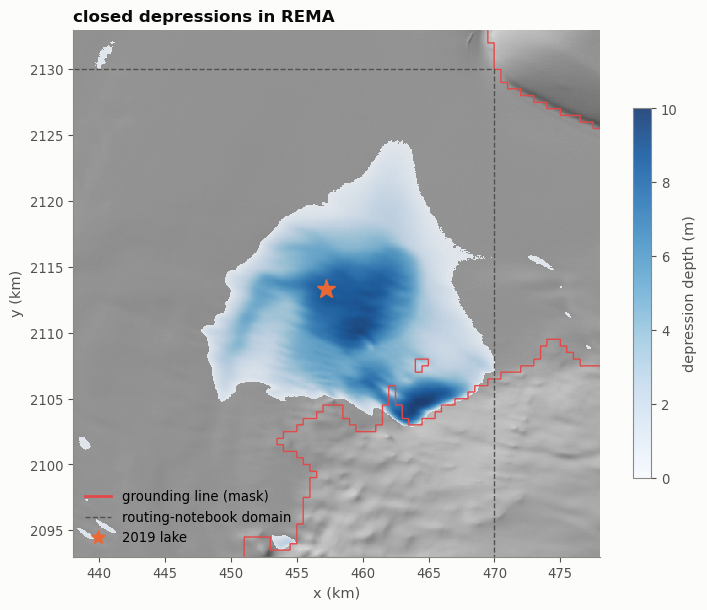

In [2]:
dep = it.depression_depth(dem.coarsen(x=2, y=2, boundary="trim").mean())

fig, ax = plt.subplots(figsize=(8.5, 8))
show_map(ax, hs, "closed depressions in REMA", cmap="gray", vmin=0, vmax=1)
im = show_map(ax, dep.where(dep > 0.3), cmap="Blues", vmin=0, vmax=10, alpha=0.85)
fig.colorbar(im, ax=ax, shrink=0.6, label="depression depth (m)")
ax.contour(floating.x / 1e3, floating.y / 1e3, floating.astype(float), [0.5], colors=ps.TENSION, linewidths=1)
x0, y0, x1, y1 = ROUTING_DOMAIN
ax.plot(np.array([x0, x1, x1, x0, x0]) / 1e3, np.array([y0, y0, y1, y1, y0]) / 1e3, color=ps.INK2, ls="--", lw=1)
ax.plot(*np.array(LAKE19) / 1e3, "*", color=ps.ELASTIC, ms=14)
ax.set(xlim=(BOUNDS[0] / 1e3, BOUNDS[2] / 1e3), ylim=(BOUNDS[1] / 1e3, BOUNDS[3] / 1e3))
ax.plot([], [], color=ps.TENSION, label="grounding line (mask)")
ax.plot([], [], color=ps.INK2, ls="--", lw=1, label="routing-notebook domain")
ax.plot([], [], "*", color=ps.ELASTIC, ms=10, label="2019 lake")
ax.legend(loc="lower left");

### Which summers had water? Every Sentinel-2 image since 2018

`it.s2_scan` reads every Sentinel-2 L2A acquisition over a 14 km window around the basin, for each melt season from October 2018 to April 2026 (206 acquisitions). For each one it counts the open water: NDWI$_{ice}$ > 0.25 and SWIR (B11) < 0.05, since water is dark at 1.6 µm. It also flags cloud as SWIR > 0.12. That flag misses thin cloud, so the thumbnails below show every December–March image that is not obviously overcast.

season
2018     6.4
2019    10.6
2020     0.0
2021     0.3
2022     0.0
2023     0.0
2024     0.0
2025     0.5


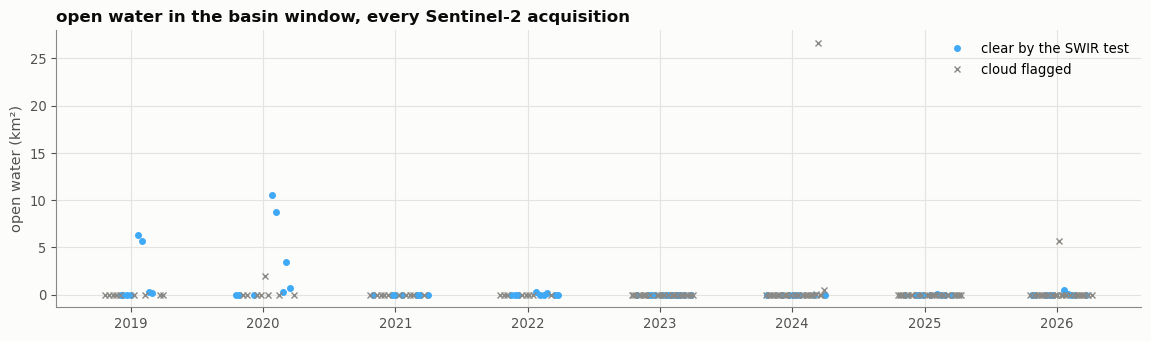

In [3]:
SEASONS = [(f"{y}-10-15", f"{y + 1}-04-15") for y in range(2018, 2026)]
WIN = (452e3, 2105e3, 466e3, 2119e3)
scan, scan_grid = it.s2_scan(WIN, SEASONS, res=40.0, verbose=False)
scan["clear"] = (scan.cloud < 0.3) & (scan.valid > 0.9)
scan["season"] = (scan.date - pd.Timedelta(days=182)).dt.year

fig, ax = plt.subplots(figsize=(14, 3.6))
ax.plot(scan.date[scan.clear], scan.water_km2[scan.clear], "o", ms=4, color=ps.WATER, label="clear by the SWIR test")
ax.plot(scan.date[~scan.clear], scan.water_km2[~scan.clear], "x", ms=4, color=ps.MUTED, label="cloud flagged")
ax.set(ylabel="open water (km²)", title="open water in the basin window, every Sentinel-2 acquisition")
ax.legend(loc="upper right")
print(scan[scan.clear].groupby("season").water_km2.max().rename("largest clear-sky water area (km²)").round(1).to_string())

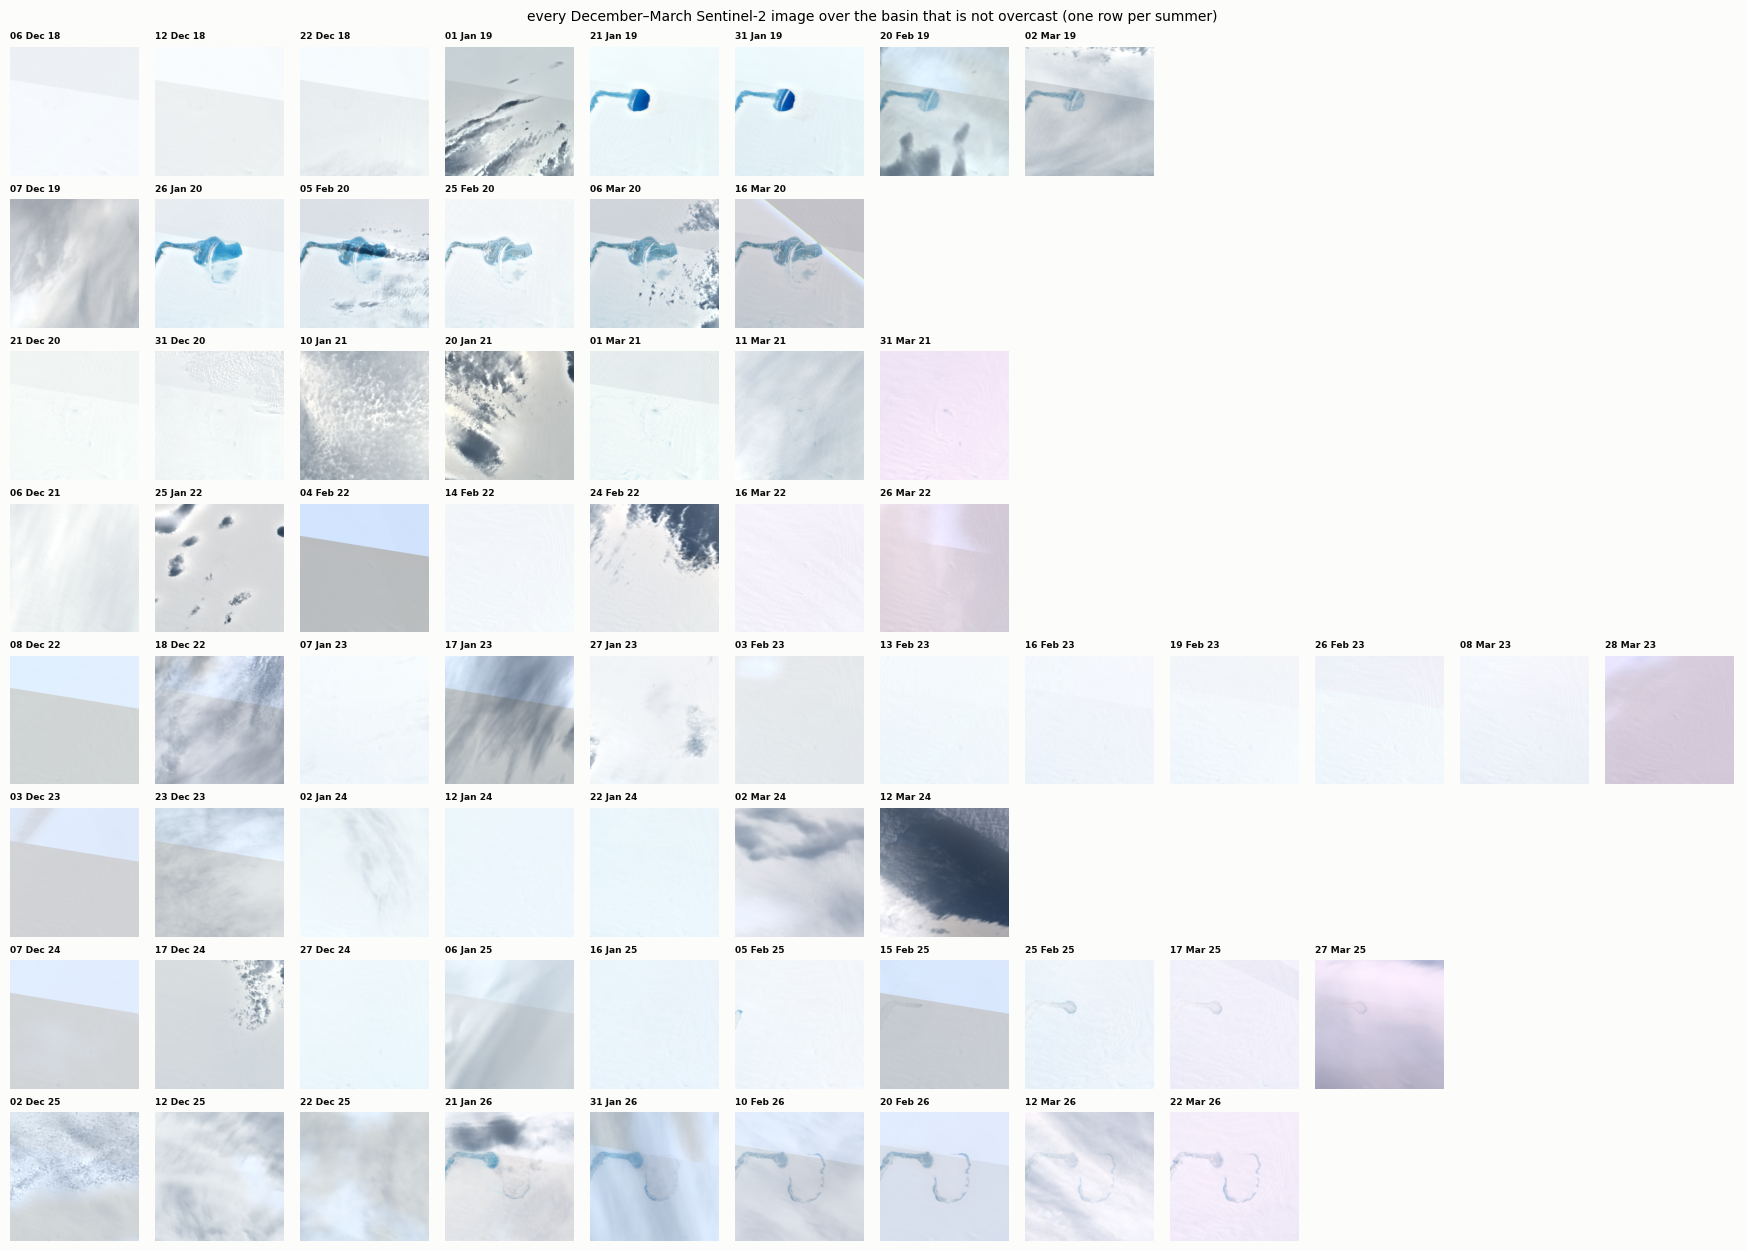

In [4]:
thumbs = scan[scan.date.dt.month.isin([12, 1, 2, 3]) & (scan.valid > 0.5) & (scan.cloud < 0.6)]
seasons = sorted(thumbs.season.unique())
ncol = int(thumbs.groupby("season").size().max())
fig, axs = plt.subplots(len(seasons), ncol, figsize=(1.45 * ncol, 1.55 * len(seasons)), constrained_layout=True)
for row, yr in zip(axs, seasons):
    for ax in row:
        ax.axis("off")
    for ax, (_, r) in zip(row, thumbs[thumbs.season == yr].iterrows()):
        ax.imshow(it.rgb(it.s2_scene(f"{r.date:%Y-%m-%d}", scan_grid, bands=("blue", "green", "red", "swir16"))))
        ax.set_title(f"{r.date:%d %b %y}", fontsize=6.5)
fig.suptitle("every December–March Sentinel-2 image over the basin that is not overcast (one row per summer)", fontsize=10);

Before ICESat-2: Landsat 8 (2014–2016) and the Planetary Computer's Sentinel-2 archive (2016–2018). Landsat scenes from 2017–2018 are in archive storage there and cannot be read.

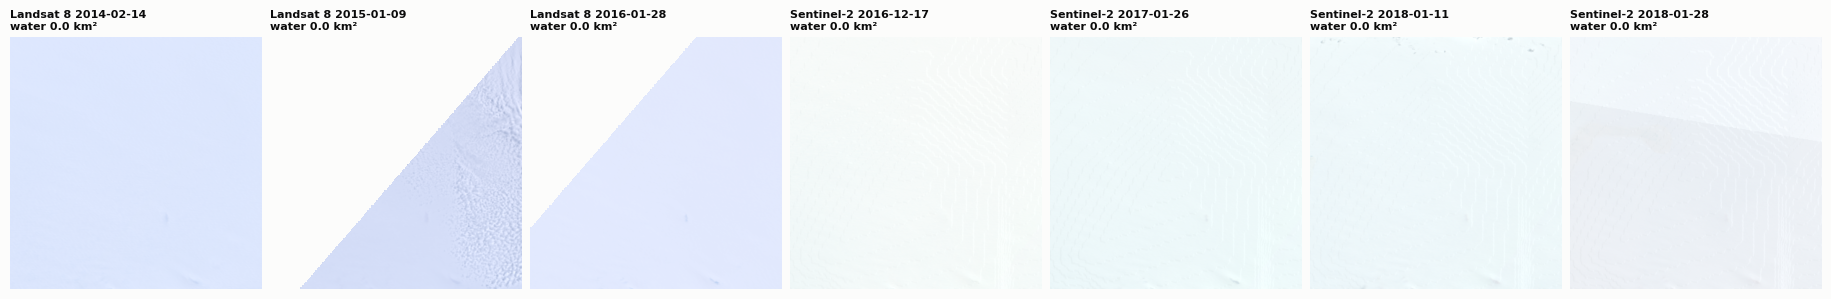

In [5]:
PRE = [("landsat-c2-l2", "2014-02-14"), ("landsat-c2-l2", "2015-01-09"), ("landsat-c2-l2", "2016-01-28"),
       ("sentinel-2-l2a", "2016-12-17"), ("sentinel-2-l2a", "2017-01-26"), ("sentinel-2-l2a", "2018-01-11"),
       ("sentinel-2-l2a", "2018-01-28")]
fig, axs = plt.subplots(1, len(PRE), figsize=(2.6 * len(PRE), 2.9), constrained_layout=True)
for ax, (coll, d) in zip(axs, PRE):
    sc = it.pc_scene(coll, d, scan_grid)
    wet = float(((it.ndwi_ice(sc) > 0.25) & (sc.swir16 < 0.05)).sum()) * 1600 / 1e6
    ax.imshow(it.rgb(sc)); ax.axis("off")
    ax.set_title(f"{'Landsat 8' if 'landsat' in coll else 'Sentinel-2'} {d}\nwater {wet:.1f} km²", fontsize=8)

**Water in the basin during the ICESat-2 era: 2019, 2020 and 2026 only.**

* **2018–19:** none on 22 December. The lake appears between 1 and 11 January 2019 and is open until early February. It is ice-covered by 20 February.
* **2019–20:** faint blue on 27 December, then a lake from 6 January to March 2020.
* **2020–21:** no water on the clear images (21 and 31 December, 1–11 March), but every January image is cloudy, so a short-lived January lake cannot be ruled out.
* **2021–22 to 2024–25:** no lake. In late February–March 2025 a small pond (≲ 0.5 km²) shows at the end of the feeder channel, west of the 2019 lake.
* **2025–26:** a channel and a lake outline from 11 January 2026, largely ice- or snow-covered by February.
* **Before ICESat-2:** none of the 2014–2018 summer images shows water in the basin, so the 2019 lake was the first in at least five years.

### Key scenes

The scenes below are the clearest of each summer that show the basin. The red line is NDWI$_{ice}$ = 0.25, the usual threshold for water on ice. The quoted open-water area is the patch of water connected to the 2019 lake.

2026 flooded footprint: 23.7 km²


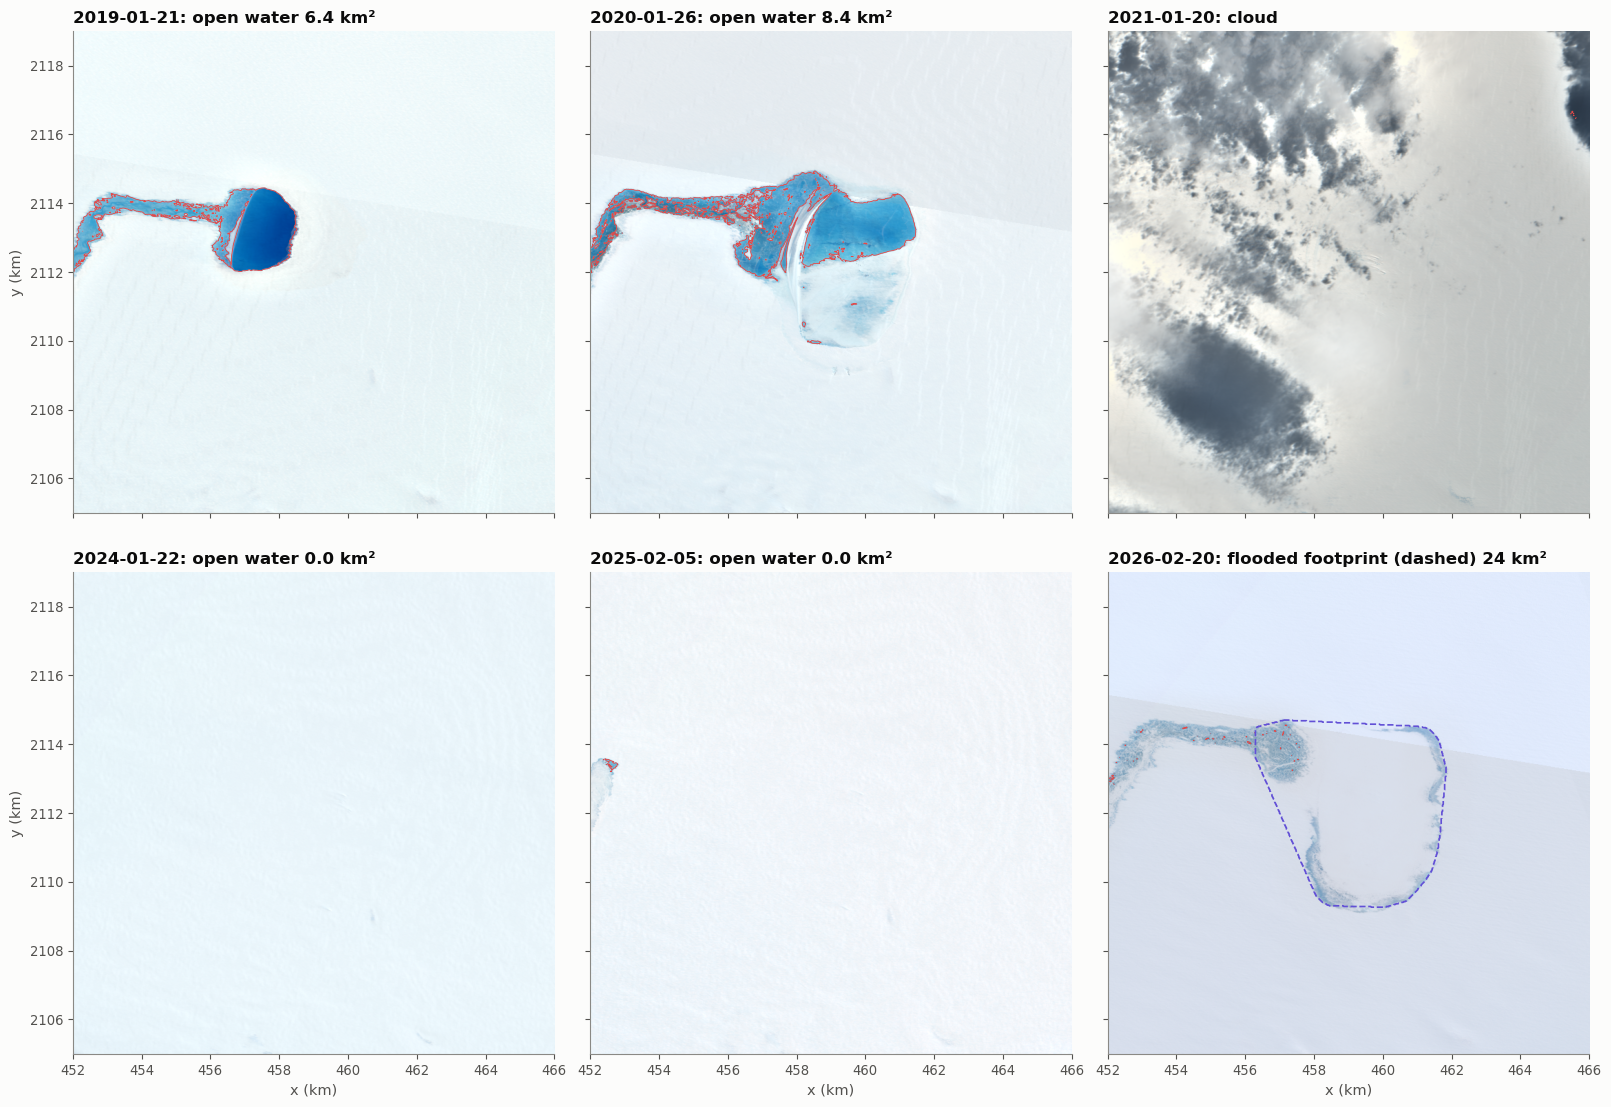

In [6]:
S2_DATES = {"2019": "2019-01-21", "2020": "2020-01-26", "2021": "2021-01-20", "2024": "2024-01-22",
            "2025": "2025-02-05", "2026": "2026-02-20"}
grid = it.make_grid(452e3, 466e3, 2105e3, 2119e3, 20.0)
scenes = {yr: it.s2_scene(d, grid) for yr, d in S2_DATES.items()}
lakes = {yr: it.lake_mask(it.ndwi_ice(s), LAKE19) for yr, s in scenes.items()}

# 2026: by 20 February only the margins are open water, so the flooded footprint is taken as the
# convex hull of the water (NDWI_ice > 0.1) east of the 2019 lake's west shore
from skimage.morphology import convex_hull_image
X2, Y2 = np.meshgrid(grid.x, grid.y)
wet26 = (it.ndwi_ice(scenes["2026"]) > 0.1).values & (X2 > 456.3e3) & (Y2 > 2108e3) & (Y2 < 2115.5e3)
lakes["2026"] = grid.copy(data=convex_hull_image(ndi.binary_opening(wet26)))
print(f"2026 flooded footprint: {float(lakes['2026'].sum()) * 400 / 1e6:.1f} km²")

fig, axs = plt.subplots(2, 3, figsize=(16, 11), sharex=True, sharey=True, constrained_layout=True)
ext = ps.map_extent(grid)
for ax, (yr, s) in zip(axs.flat, scenes.items()):
    ax.imshow(it.rgb(s), extent=ext)
    ax.contour(grid.x / 1e3, grid.y / 1e3, it.ndwi_ice(s), [0.25], colors=ps.TENSION, linewidths=0.6)
    if yr == "2026":
        ax.contour(grid.x / 1e3, grid.y / 1e3, lakes[yr].astype(float), [0.5], colors=ps.ACCENT, linewidths=1.2, linestyles="--")
    ax.set_title(f"{s.date}: " + ("cloud" if yr == "2021" else
                 f"flooded footprint (dashed) {float(lakes[yr].sum()) * 400 / 1e6:.0f} km²" if yr == "2026" else
                 f"open water {float(lakes[yr].sum()) * 400 / 1e6:.1f} km²"))
    ax.set_aspect("equal"); ax.grid(False)
for ax in axs[-1]:
    ax.set_xlabel("x (km)")
for ax in axs[:, 0]:
    ax.set_ylabel("y (km)")

In [7]:
# the 2019 lake body without its feeder channel, for the plate model below
body = ndi.binary_opening(lakes["2019"].values, iterations=8)
lab, n = ndi.label(body)
body = grid.copy(data=lab == np.argmax(ndi.sum(body, lab, range(1, n + 1))) + 1)
cx, cy = float(grid.x.where(body).mean()), float(grid.y.where(body).mean())
A19 = float(body.sum()) * 400
print(f"2019 lake body: {A19 / 1e6:.2f} km² (equivalent radius {np.sqrt(A19 / np.pi):.0f} m), "
      f"centred at ({cx / 1e3:.1f}, {cy / 1e3:.1f}) km")

2019 lake body: 3.94 km² (equivalent radius 1120 m), centred at (457.4, 2113.3) km


* **2019:** a deep (dark blue) round lake about 2.4 km across, fed from the west by a channel. Chen et al. give 4.35 km² on 31 January 2019; the area here includes the channel.
* **2020:** a larger, paler and so shallower lake that spreads east, with a broad pale area (refrozen or slushy) to the south.
* **2021:** cloud.
* **2022–2025:** no visible water. Chen et al. note none in 2022 either.
* **2026:** a feeder channel and a lake outline about 4–5 km across, whose middle looks frozen or snow-covered by 20 February. Its water lies over the same ground as the 2020 lake. Only the margins are open water, so the dashed line (the convex hull of that water) stands in for the flooded footprint.

## 3. ICESat-2 over the basin

The ATL06 heights `h_li` carry neither the ocean tide nor the dynamic atmosphere correction (DAC), so both are subtracted here (`h`). Each pass is then compared with REMA (`res = h - REMA`). REMA is a fixed reference: when two passes are a few hundred metres apart, differencing their residuals removes the topography between them.

In [8]:
atl = it.fetch_atl06(BOUNDS)
atl = atl[atl.atl06_quality_summary == 0]
atl = it.add_reference(atl, dem, floating)
print(f"{len(atl):,} good ATL06 segments on {atl.rgt.nunique()} reference ground tracks, "
      f"{atl.time.min():%d %b %Y} to {atl.time.max():%d %b %Y}")
near = it.passes_near(atl, *LAKE19, 1500.0)
near.groupby(["rgt", "cycle"]).agg(date=("time", lambda t: f"{t.iloc[0]:%Y-%m-%d}"), closest_m=("closest_m", "min"),
                                    beams=("beam", lambda b: ",".join(map(str, b))),
                                    tide_m=("tide_ocean", "median")).reset_index().sort_values("date")

1,815,837 good ATL06 segments on 11 reference ground tracks, 15 Oct 2018 to 08 Jul 2026


,rgt,cycle,date,closest_m,beams,tide_m
21,762,1,2018-11-17,414.31,"30,40",0.04
22,762,2,2019-02-16,870.01,"50,60",-0.85
36,1204,2,2019-03-17,1081.74,"10,20",-0.78
37,1257,2,2019-03-20,768.68,"10,20",0.39
0,312,3,2019-04-18,436.57,"50,60",0.46
23,762,3,2019-05-18,753.28,"50,60",0.83
24,762,5,2019-11-15,754.91,"50,60",0.58
1,312,6,2020-01-16,428.99,"50,60",0.02
25,762,7,2020-05-15,732.64,"50,60",0.20
2,312,8,2020-07-15,420.87,50,-0.52


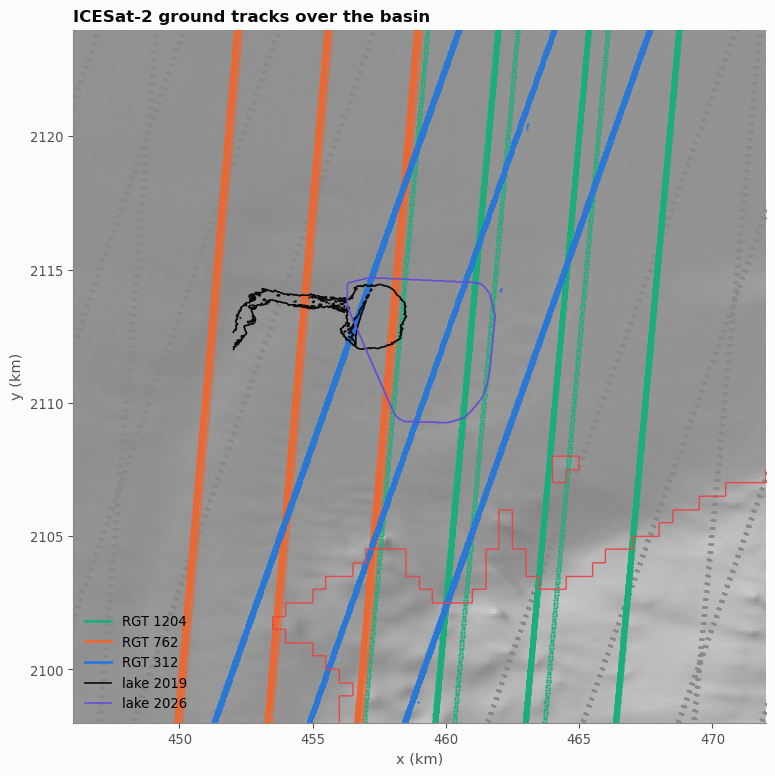

In [9]:
fig, ax = plt.subplots(figsize=(9, 9))
show_map(ax, hs, "ICESat-2 ground tracks over the basin", cmap="gray", vmin=0, vmax=1)
sub = atl[(atl.cycle >= 3) & (atl.segment_id % 15 == 0)]   # thin out by segment, not by row
ax.scatter(sub.x / 1e3, sub.y / 1e3, s=0.3, color=ps.MUTED, alpha=0.4, rasterized=True)
for rgt, c in [(1204, ps.ISO), (762, ps.ELASTIC), (312, ps.VISCO)]:
    q = atl[(atl.rgt == rgt) & (atl.cycle >= 2) & (atl.segment_id % 5 == 0)]
    ax.scatter(q.x / 1e3, q.y / 1e3, s=0.6, color=c, rasterized=True)
    ax.plot([], [], color=c, label=f"RGT {rgt}")
for yr, c in [("2019", ps.INK), ("2026", ps.ACCENT)]:
    ax.contour(grid.x / 1e3, grid.y / 1e3, lakes[yr].astype(float), [0.5], colors=c, linewidths=1.2)
    ax.plot([], [], color=c, lw=1.2, label=f"lake {yr}")
ax.contour(floating.x / 1e3, floating.y / 1e3, floating.astype(float), [0.5], colors=ps.TENSION, linewidths=1)
ax.set(xlim=(446, 472), ylim=(2098, 2124))
ax.legend(loc="lower left", markerscale=10);

Two tracks matter most:

* **RGT 762** runs nearly north–south. Its right beam pair crosses the 2019 lake about 0.7 km east of the middle, and the grounding line 8 km south of it. Its centre and left pairs run 3.3 and 6.6 km further west.
* **RGT 312** runs north-north-east. One pair grazes the 2019 lake's west shore, and the pair 3.3 km to the east crosses the middle of the area flooded in 2020 and 2026. It has passes in early or mid-January most years.

In ICESat-2's first two cycles (October 2018 to March 2019) the beams were not yet pointed at the reference tracks. The 17 November 2018 pass of RGT 762 lies about 3 km east of the later ones, so its *centre* pair runs where later passes have their *right* pair. Passes are therefore paired by position, not by beam name (`it.pass_difference`, any segment within 600 m). From cycle 3 (March 2019) the repeats are within a few tens of metres.

## 4. How stiff is the shelf here? Tidal flexure at the grounding line

RGT 762's right pair crosses the grounding line about 8 km south of the lake. Between two passes the floating ice rises and falls with the tide while the grounded ice stays put, and the shelf bends between them. The bend is the classic hinge profile of an elastic beam clamped at the hinge:

$$\Delta h(s) = A\left[1 - e^{-\beta s}(\cos\beta s + \sin\beta s)\right],\qquad \beta = \frac{1}{\sqrt2\,\ell},\qquad \ell = (D/\rho_{sw} g)^{1/4}.$$

The fits below use heights with no ocean-tide correction. They cover every pair of passes whose modelled tides differ by more than 0.8 m, over the 7 km south of the lake's influence.

In [10]:
atl["res_notide"] = atl.h_li - atl.dac - atl.rema
win = (2101e3, 2108.3e3)
fits, curves = [], []
cyc = sorted(atl[(atl.rgt == 762) & (atl.cycle >= 2)].cycle.unique())
for i, ca in enumerate(cyc):
    for cb in cyc[i + 1:]:
        d = it.pass_difference(atl, 762, ca, cb, max_sep=300, beams=[50, 60], field="res_notide")
        if len(d) == 0:
            continue
        for beam, q in d[(d.y > win[0]) & (d.y < win[1])].groupby("beam"):
            dT = q.tide.median()
            if abs(dT) < 0.8 or len(q) < 150:
                continue
            try:
                p, cov = curve_fit(it.hinge, q.y, q.dh_raw, p0=[dT, 2104.8e3, 500, 0],
                                   bounds=([-3, 2102e3, 50, -2], [3, 2107e3, 5000, 2]))
            except RuntimeError:
                continue
            rms = np.std(q.dh_raw - it.hinge(q.y, *p))
            fits.append(dict(beam=beam, cycles=f"{ca}-{cb}", dtide=dT, A=p[0], A_over_dtide=p[0] / dT,
                             hinge_y_km=p[1] / 1e3, ell_m=p[2], rms_m=rms))
            curves.append((q.y.values, q.dh_raw.values / dT, p))
fits = pd.DataFrame(fits)
good = fits[(fits.rms_m < 0.3) & fits.A_over_dtide.between(0.7, 1.5)]
ELL_TIDE = float(good.ell_m.median())
q25, q75 = good.ell_m.quantile([0.25, 0.75])
print(f"{len(good)} of {len(fits)} fits kept; flexural length from tides: median {ELL_TIDE:.0f} m "
      f"(interquartile {q25:.0f}–{q75:.0f} m); hinge at y = {good.hinge_y_km.median():.2f} km")
print(f"A / modelled tide difference: median {good.A_over_dtide.median():.2f}")
for H in (300.0, 400.0):
    print(f"  for H = {H:.0f} m this needs E = {it.youngs_modulus(ELL_TIDE, H) / 1e9:.2f} GPa "
          f"(E = 1 GPa would give ell = {it.flexural_length(1e9, H):.0f} m)")
good.sort_values("rms_m").head(8)

20 of 32 fits kept; flexural length from tides: median 502 m (interquartile 388–575 m); hinge at y = 2104.67 km
A / modelled tide difference: median 1.07
  for H = 300 m this needs E = 0.26 GPa (E = 1 GPa would give ell = 704 m)
  for H = 400 m this needs E = 0.11 GPa (E = 1 GPa would give ell = 873 m)


,beam,cycles,dtide,A,A_over_dtide,hinge_y_km,ell_m,rms_m
1,60,2-3,1.70,1.57,0.93,2104.72,468.12,0.09
3,60,2-5,1.44,1.41,0.98,2104.69,492.46,0.09
5,60,2-7,1.06,1.19,1.13,2104.65,512.07,0.12
0,50,2-3,1.70,1.59,0.94,2104.77,423.65,0.12
2,50,2-5,1.44,1.40,0.97,2104.60,533.17,0.12
4,50,2-7,1.06,1.21,1.14,2104.66,473.59,0.14
29,60,5-14,-1.00,-1.09,1.09,2104.93,280.38,0.18
6,50,2-11,1.21,1.43,1.18,2104.54,540.32,0.19


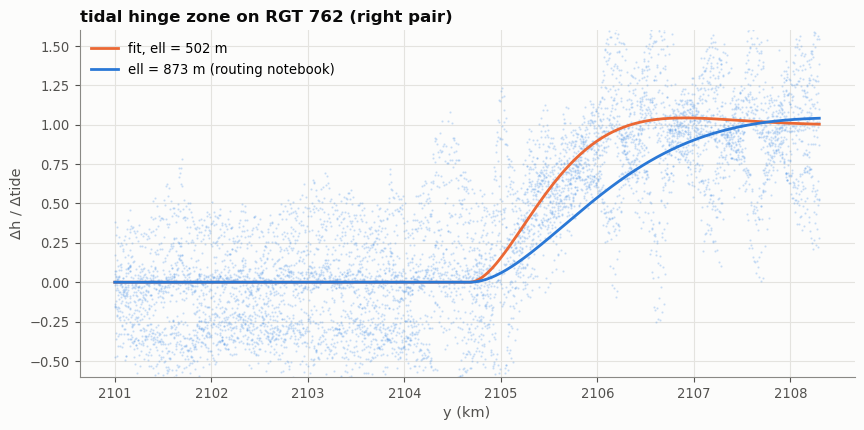

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
yy = np.linspace(*win, 400)
for (y_, d_, p), (_, row) in zip(curves, fits.iterrows()):
    if row.name in good.index:
        ax.plot(y_ / 1e3, d_, ".", ms=1.2, color=ps.SEQ[2], alpha=0.25, rasterized=True)
for ell, c, lab in [(ELL_TIDE, ps.ELASTIC, f"fit, ell = {ELL_TIDE:.0f} m"), (873.0, ps.VISCO, "ell = 873 m (routing notebook)")]:
    ax.plot(yy / 1e3, it.hinge(yy, 1.0, good.hinge_y_km.median() * 1e3, ell, 0.0), color=c, lw=2, label=lab)
ax.set(xlabel="y (km)", ylabel="Δh / Δtide", ylim=(-0.6, 1.6), title="tidal hinge zone on RGT 762 (right pair)")
ax.legend(loc="upper left");

The tide bends the shelf over a flexural length of a few hundred metres. That is about half the 873 m of the routing notebook's plate ($H$ = 400 m, $E$ = 1 GPa). With $H$ = 300–400 m it implies an effective $E$ of only about 0.1–0.3 GPa. Tidal flexure often gives a low effective modulus, because ice creeps even over a tidal cycle and because grounding zones are not clean hinges. So read $\ell_{tide}$ as the shortest length scale the plate is likely to have. For loads that stay for weeks the plate relaxes further, towards local isostasy.

## 5. What a plate predicts for the 2019 lake

The load is the 2019 lake body mapped above, with a bowl-shaped depth that peaks at 8 m (Chen et al.) and falls to zero at the shore. Three plates from this folder's `SpectralPlate` bear it:

* elastic with $\ell = \ell_{tide}$;
* elastic with the routing notebook's $H$ = 400 m and $E$ = 1 GPa ($\ell$ = 873 m);
* viscoelastic with the routing notebook's $\eta = 10^{14}$ Pa s, filled linearly over 30 days from 25 December 2018 and then left in place (frozen, not drained).

The total sag volume is the same for every plate ($\rho_w V/\rho_{sw}$). What changes is how far beyond the shore it reaches.

In [12]:
DMAX = 8.0
pad = 300                                                   # 40 m cells: 12 km of padding each side
b40 = body.coarsen(x=2, y=2).max()
dist = ndi.distance_transform_edt(b40.values) * 40.0
depth = DMAX * (1 - (1 - dist / dist.max()) ** 2) * b40.values
depth = np.pad(depth, pad)
xs = np.r_[b40.x.values[0] - 40 * np.arange(pad, 0, -1), b40.x.values, b40.x.values[-1] + 40 * np.arange(1, pad + 1)]
ys = np.r_[b40.y.values[0] + 40 * np.arange(pad, 0, -1), b40.y.values, b40.y.values[-1] - 40 * np.arange(1, pad + 1)]
V19 = depth.sum() * 40 * 40
print(f"lake load: {V19 / 1e6:.1f} Mm³ over {float(b40.sum()) * 1600 / 1e6:.2f} km², mean depth {V19 / (float(b40.sum()) * 1600):.1f} m; "
      f"sag volume it must produce: {it.RHO_W * V19 / it.RHO_SW / 1e6:.1f} Mm³")

H = 400.0
plates = {f"elastic, ell = {ELL_TIDE:.0f} m (tides)": IceShelf(H=H, E=it.youngs_modulus(ELL_TIDE, H)),
          "elastic, ell = 873 m (routing nb)": IceShelf(H=H, E=1e9)}
q = it.RHO_W * it.G * depth
pred = {}
for name, shelf in plates.items():
    w = SpectralPlate(xs.size, ys.size, 40.0, shelf, x=xs, y=ys).elastic(q)
    pred[name] = xr.DataArray(w, coords={"y": ys, "x": xs}, dims=("y", "x"))
pred["isostatic"] = xr.DataArray(it.RHO_W / it.RHO_SW * depth, coords={"y": ys, "x": xs}, dims=("y", "x"))

# viscoelastic: routing-notebook plate, fill over 30 days then hold; keep the ICESat-2 dates
FILL0 = pd.Timestamp("2018-12-25")
DATES = {"2019-02-16": None, "2019-05-18": None, "2019-11-15": None}
days = np.r_[np.arange(0, 31, 1.0), np.arange(32, 330, 2.0)]
ramp = np.clip(days / 30.0, 0, 1)
store = [int(np.argmin(abs(days - (pd.Timestamp(d) - FILL0).days))) for d in DATES]
ve = SpectralPlate(xs.size, ys.size, 40.0, IceShelf(H=H, E=1e9, eta=1e14), x=xs, y=ys).run(
    days * SECONDS_PER_DAY, (q, ramp), store=store, store_mu=False)
for k, d in enumerate(DATES):
    pred[f"viscoelastic (eta 1e14), {d}"] = ve.w.isel(time=k).drop_vars(["time", "time_days"])
depth_da = xr.DataArray(depth, coords={"y": ys, "x": xs}, dims=("y", "x"))
for name, w in pred.items():
    print(f"{name:>38}: max sag {float(w.max()):.2f} m, sag volume {float(w.sum()) * 1600 / 1e6:.1f} Mm³")

lake load: 17.2 Mm³ over 4.09 km², mean depth 4.2 m; sag volume it must produce: 16.8 Mm³


          elastic, ell = 502 m (tides): max sag 4.32 m, sag volume 16.8 Mm³
     elastic, ell = 873 m (routing nb): max sag 2.03 m, sag volume 16.8 Mm³
                             isostatic: max sag 7.78 m, sag volume 16.8 Mm³
   viscoelastic (eta 1e14), 2019-02-16: max sag 4.89 m, sag volume 16.8 Mm³
   viscoelastic (eta 1e14), 2019-05-18: max sag 6.57 m, sag volume 16.8 Mm³
   viscoelastic (eta 1e14), 2019-11-15: max sag 7.49 m, sag volume 16.8 Mm³


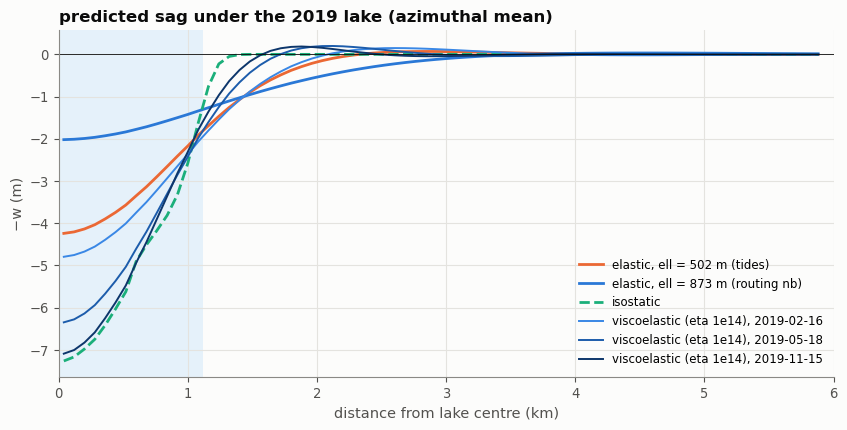

In [13]:
# radial profiles from the lake centre (azimuthal means)
R = np.hypot(*np.meshgrid(xs - cx, ys - cy))
rb = np.arange(0, 6000, 80.0)
def radial(a):
    i = np.digitize(R.ravel(), rb)
    return np.array([np.asarray(a).ravel()[i == k].mean() for k in range(1, rb.size)])
rc = 0.5 * (rb[1:] + rb[:-1])
rs = np.sqrt(A19 / np.pi)
fig, ax = plt.subplots(figsize=(10, 4.5))
cols = [ps.ELASTIC, ps.VISCO, ps.ISO, ps.SEQ[3], ps.SEQ[6], ps.SEQ[9]]
for (name, w), c in zip(pred.items(), cols):
    ax.plot(rc / 1e3, -radial(w), color=c, lw=2 if "visco" not in name else 1.4, ls="--" if name == "isostatic" else "-", label=name)
ax.axvspan(0, rs / 1e3, color=ps.WATER, alpha=0.12, lw=0)
ax.axhline(0, color=ps.INK, lw=0.6)
ax.set(xlabel="distance from lake centre (km)", ylabel="−w (m)", title="predicted sag under the 2019 lake (azimuthal mean)",
       xlim=(0, 6))
ax.legend(fontsize=8.5, loc="lower right");

Beyond the shore, which is where an altimeter sees the deflection directly, the predicted sag is short-ranged. Every plate is 1–2 m down at the shore. The sag then decays to less than 0.3 m within about 1 km ($\ell$ = 502 m) or 2 km ($\ell$ = 873 m), with a small forebulge beyond. The viscoelastic plate moves most of the way to isostasy by May: its sag deepens under the water and draws in outside it. Its relaxation time is about 4 days, but longer for short wavelengths. In every case the pond's water surface ends up above the old floor by $d - w$. That is about 0.2 m if the support is isostatic and several metres if it is elastic.

## 6. The water surface against the water-free surface before filling

The most direct test of whether the shelf sinks under a lake compares where the lake's water surface sits with the surface measured at the same spot before any water arrived. ICESat-2 crossed open water in the basin three times: on 16 February 2019 (RGT 762) and twice on 16 January 2020 (two beam pairs of RGT 312). Each crossing has a water-free pass on the same track before it, on 17 November 2018 and 18 April 2019. The 2019 lake had frozen over by 18 April 2019, but the ground under the 2020 crossing on dry snow had never been flooded.

For a lake of depth $d$, assuming the water is imported and the old surface does not melt:

| | rigid shelf | elastic plate | local isostasy (a relaxed viscoelastic plate) |
|---|---|---|---|
| water surface − surface before, mid-lake | $+d$ | $+(d - w)$ | $+0.03\,d$ |
| bed − surface before | 0 | $-w$ | $-0.97\,d$ |
| water surface − surface before, at the shore | 0 | $-w_{shore} < 0$ | 0 |
| dry ice beyond the shore | 0 | $-w$, decaying over a few $\ell$ | 0 |

On a rigid shelf a lake's surface is the contour of the old topography along its shoreline. Only a shelf that sinks can hold deep water whose surface is no higher than the ground was. And only a plate that bends, rather than sinking point by point, can put water over ground that used to be *higher* than the water.

`it.wet_crossing` takes the water surface and bed from the ATL03 photons of one beam: the surface is the densest 0.1 m height bin in each 40 m bin. The bed is a distinct peak in photon counts below the surface, with depths corrected for refraction (×1/1.336). The surface before filling comes from the earlier pass's ATL06 segments, moved onto the new beam with REMA. The far-field offset is removed as in the rest of the notebook. Heights are tide- and DAC-corrected.

In [14]:
BOX762 = (LAKE19[0] - 4e3, LAKE19[1] - 5e3, LAKE19[0] + 4e3, LAKE19[1] + 5e3)
BOX312 = (455e3, 2107e3, 465e3, 2119e3)
CROSSINGS = [  # label, day, rgt, wet cycle, reference cycle, ATL03 spot, box, seed (y or y-range on the water)
    ("2019 lake (RGT 762)", "2019-02-16", 762, 2, 1, 5, BOX762, 2113.2e3),
    ("2020: the 2019 lake reopened (RGT 312)", "2020-01-16", 312, 6, 3, 1, BOX312, 2113.3e3),
    ("2020: new water over dry snow (RGT 312)", "2020-01-16", 312, 6, 3, 3, BOX312, (2110.5e3, 2111.5e3)),
]
wet = {}
for label, day, rgt, cw, cr, spot, box, seed in CROSSINGS:
    ph = it.fetch_atl03(box, day, rgt)
    sb, sm = it.wet_crossing(atl, ph, rgt, cw, cr, spot, dem, far, seed, tol=0.2)
    wet[label] = (ph, sb, sm)
tab = pd.DataFrame([dict(crossing=k, **{c: v[2][c] for c in ("wet", "ref", "water_level", "length_km", "level_minus_floor",
                     "level_minus_shore_south", "level_minus_shore_north", "depth_median", "depth_max", "floor_drop", "sep_m")})
                    for k, v in wet.items()]).set_index("crossing")
tab.T.round(2)

/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


crossing,2019 lake (RGT 762),2020: the 2019 lake reopened (RGT 312),2020: new water over dry snow (RGT 312)
wet,2019-02-16,2020-01-16,2020-01-16
ref,2018-11-17,2019-04-18,2019-04-18
water_level,39.64,39.88,39.76
length_km,2.48,2.0,5.72
level_minus_floor,-0.19,0.06,-0.18
level_minus_shore_south,-0.61,0.14,-1.92
level_minus_shore_north,-1.03,-0.5,-0.92
depth_median,NaN,NaN,7.75
depth_max,NaN,NaN,8.9
floor_drop,NaN,NaN,7.83


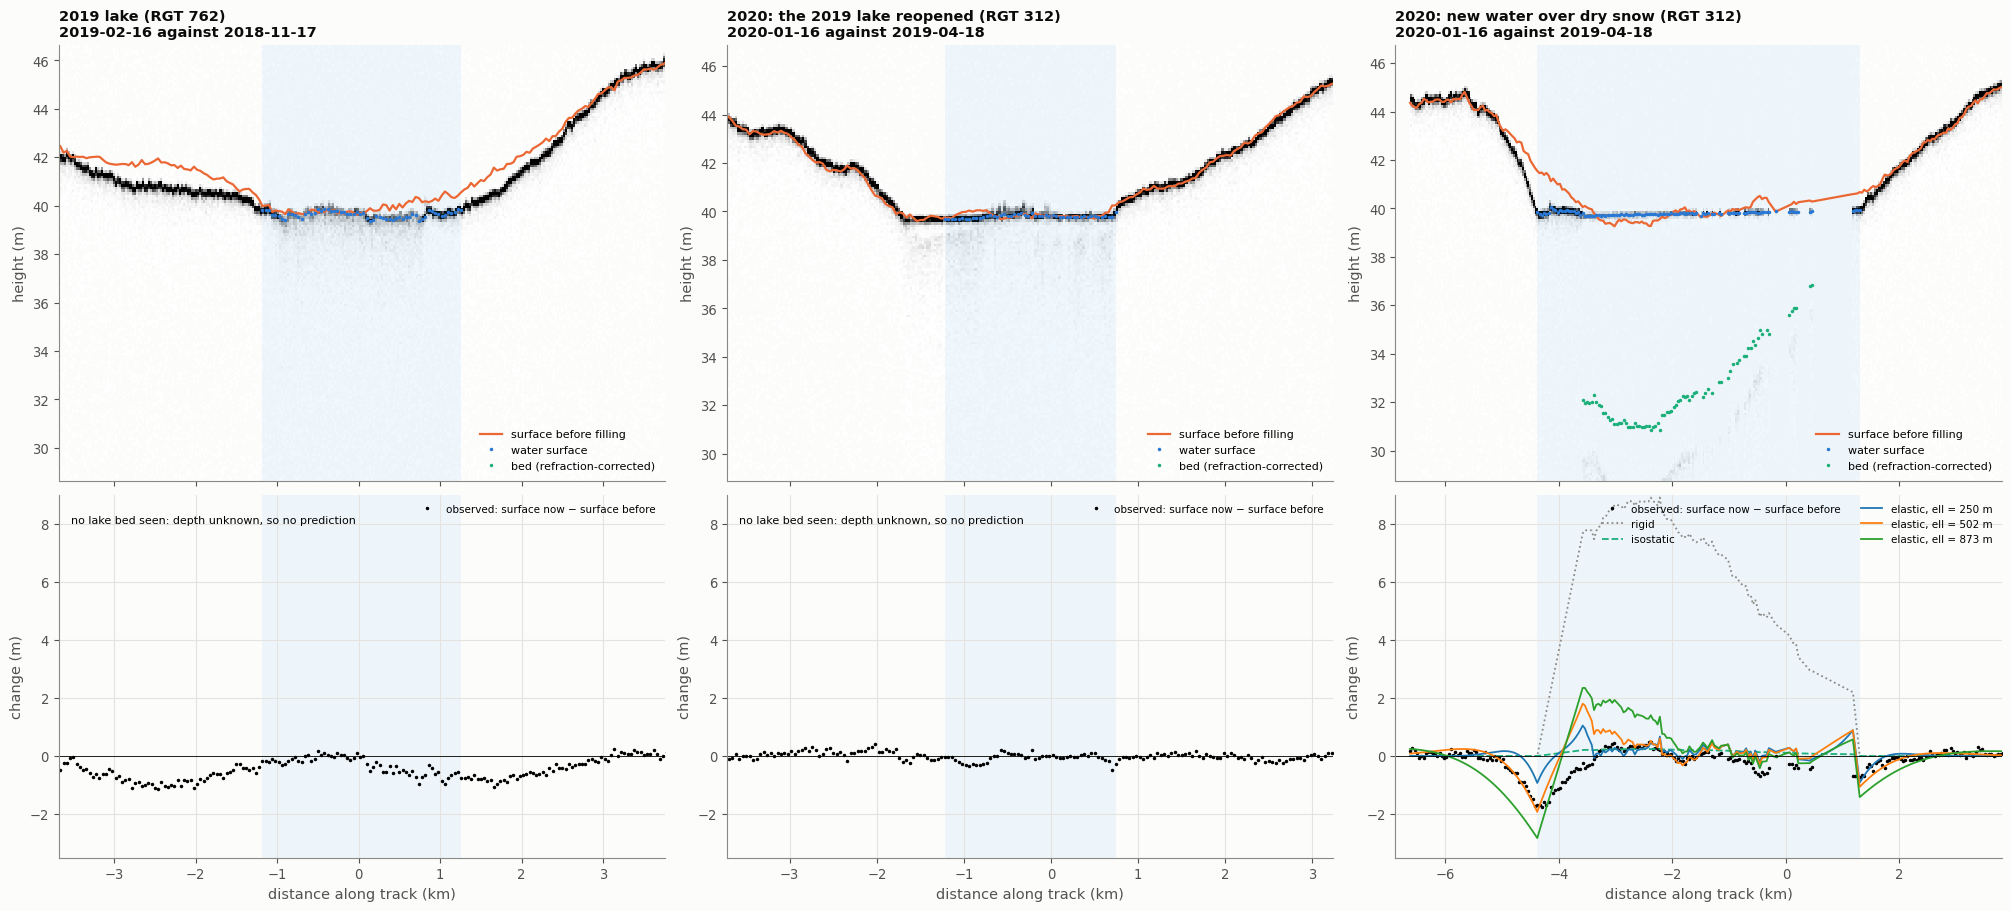

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(20, 9), sharex="col", gridspec_kw=dict(height_ratios=[1.2, 1]), constrained_layout=True)
for col, (label, (ph, sb, sm)) in enumerate(wet.items()):
    cpred = it.crossing_predictions(sb, sm, ells=(250.0, ELL_TIDE, 873.0)) if sm["bed_fraction"] > 0.3 else None
    it.plot_crossing(axs[:, col], ph, sb, sm, pred=cpred, hlim=(sm["water_level"] - 11, sm["water_level"] + 7))
    w = sb[sb.water]
    axs[0, col].set_title(f"{label}\n{sm['wet']} against {sm['ref']}", fontsize=10.5)
    axs[0, col].set_xlim(w.s.min() / 1e3 - 2.5, w.s.max() / 1e3 + 2.5)
    axs[1, col].set_ylim(-3.5, 9)
    if cpred is None:
        axs[1, col].text(0.02, 0.92, "no lake bed seen: depth unknown, so no prediction", transform=axs[1, col].transAxes, fontsize=8)

Along each crossing, the orange line is the surface before filling and the blue dots are the water surface. The green dots are the bed, where ATL03 sees one. In the bottom row, the black dots are the observed change; the lines are what a rigid shelf, three elastic plates and local isostasy predict from the measured water depth.

* **New water on dry snow (2020, right).** ICESat-2 sees the bed through ~8 m of water (median 7.8 m, up to 8.9 m) along a 5.7 km crossing. Yet over most of the crossing the water surface lies within 0.2 m of the snow surface measured nine months earlier. On a rigid shelf this water would stand ~8 m above the old surface (dotted line); instead the floor is 7.8 m *below* it. The elastic plates leave the water 0.5–2.4 m above the old surface over parts of the lake. Local isostasy (+0.2 m) fits the middle of the lake.
* **At the shores the water lies 0.9–1.9 m below where the snow surface was.** Local isostasy cannot do that. The dips match what the $\ell \approx$ 500 m plate does at the edges of the load: −1.8 m in the south, −0.7 m in the north. The likely picture is a viscoelastic plate part-way through relaxing. The broad interior has relaxed to isostasy, while the sharp edges, which relax more slowly ($\tau[1 + (2\pi\ell/\lambda)^4]$), are still bent. Extra load or melt at the shore would also lower it.
* **The reopened 2019 lake and the 2019 lake (left, middle).** The water surface is within ±0.2 m of the frozen or snow-covered surface it replaced. The water column scatters photons too strongly for a bed to be seen, so the depth is unknown. In 2019 the dry ice beside the lake dropped ~1 m.

**So yes: where water fills previously dry ground, ICESat-2 sees the expected deflection.** Mid-lake it is the long-time, near-isostatic limit of the viscoelastic plate, not its instantaneous elastic response. At the shores it still looks like elastic bending with $\ell \approx$ 0.5 km. The one alternative IS-2 cannot rule out is a hollow that was ~8 m deep but filled flush with snow before the water came: on a rigid shelf the water would then also sit at the old surface. But that leaves the shores where they were, and here they dropped by 1–2 m.

## 7. The 2019 fill along RGT 762

### Elevation change against November 2018

`dh` below is the change in REMA residual from the 17 November 2018 pass to each later pass. Each later segment is paired with the nearest November segment, 230–450 m away. The far-field median is removed from each pass: floating ice more than 7.5 km from the basin and more than 3 km from grounded ice. The thin lines are the plate predictions from Section 5, sampled along the 16 February track. On dry ice the prediction is $-w$; over the pond it is $d - w$, the new water surface relative to the old floor.

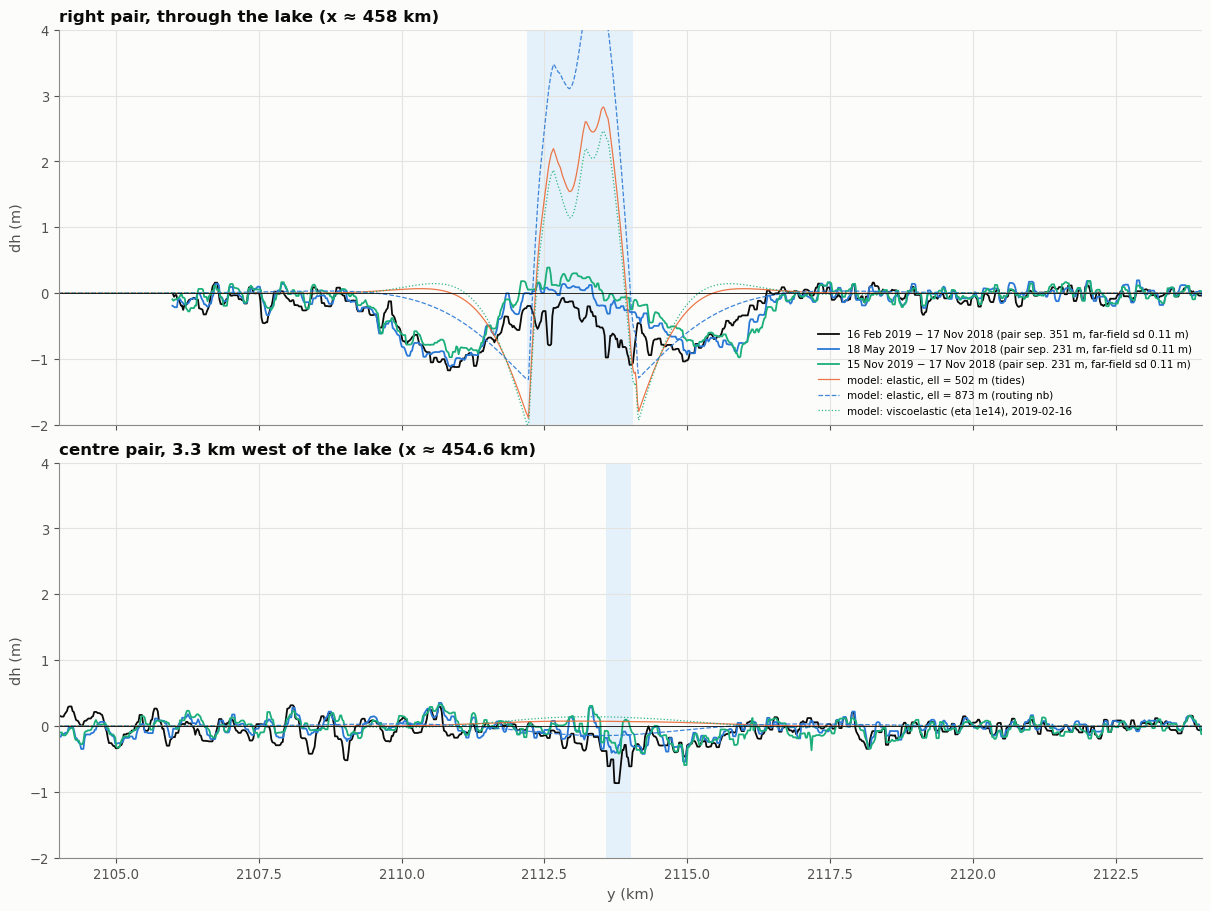

In [16]:
def sample(da, x, y):
    return da.interp(x=xr.DataArray(np.asarray(x)), y=xr.DataArray(np.asarray(y))).values

d19 = {c: it.pass_difference(atl, 762, 1, c, max_sep=600, far=far) for c in (2, 3, 5)}
fig, axs = plt.subplots(2, 1, figsize=(12, 9), sharex=True, constrained_layout=True)
for ax, beams, title in [(axs[0], [50, 60], "right pair, through the lake (x ≈ 458 km)"),
                         (axs[1], [30, 40], "centre pair, 3.3 km west of the lake (x ≈ 454.6 km)")]:
    for (c, d), col in zip(d19.items(), [ps.INK, ps.VISCO, ps.ISO]):
        q = d[d.beam == beams[0]]
        q = q[q.dgl > 1500]
        ax.plot(q.y / 1e3, it.smooth(q.dh), color=col, lw=1.3,
                label=f"{q.time.iloc[0]:%d %b %Y} − 17 Nov 2018 (pair sep. {q.sep.median():.0f} m, far-field sd {q[q.far].dh.std():.2f} m)")
    q = d19[2][d19[2].beam == beams[0]]
    lake_d = sample(depth_da, q.x, q.y)
    for (name, w), col, ls in [(list(pred.items())[0], ps.ELASTIC, "-"), (list(pred.items())[1], ps.VISCO, "--"),
                               (list(pred.items())[3], ps.ISO, ":")]:
        ax.plot(q.y / 1e3, lake_d - sample(w, q.x, q.y), color=col, lw=0.9, ls=ls, alpha=0.9, label=f"model: {name}")
    inl = lakes["2019"].sel(x=xr.DataArray(q.x.values), y=xr.DataArray(q.y.values), method="nearest").values
    if inl.any():
        ax.axvspan(q.y.values[inl].min() / 1e3, q.y.values[inl].max() / 1e3, color=ps.WATER, alpha=0.12, lw=0)
    ax.axhline(0, color=ps.INK, lw=0.6)
    ax.set(ylabel="dh (m)", title=title, ylim=(-2, 4), xlim=(2104, 2124))
axs[0].legend(fontsize=7.5, loc="lower right", ncol=1)
axs[1].set_xlabel("y (km)");

In [17]:
# numbers: sag beside the lake, and a rough force-balance check (axisymmetric about the lake centre)
q = d19[2][(d19[2].beam == 50) & (d19[2].dgl > 1500)].copy()
q["r"] = np.hypot(q.x - cx, q.y - cy)
inl = lakes["2019"].sel(x=xr.DataArray(q.x.values), y=xr.DataArray(q.y.values), method="nearest").values
south = q[(q.y < cy) & ~inl & (q.r < 3500)]
north = q[(q.y > cy) & ~inl & (q.r < 3500)]
print(f"Feb 2019, dry ice within 3.5 km of the lake centre: lowest 5% of dh = {south.dh.quantile(0.05):.2f} m (south), "
      f"{north.dh.quantile(0.05):.2f} m (north); over the pond: median {q[inl].dh.median():+.2f} m")
out = q[~inl & (q.r > rs)]
rb2 = np.arange(rs, 5000, 100.0)
prof = out.groupby(pd.cut(out.r, rb2), observed=False).dh.median().values
rmid = 0.5 * (rb2[1:] + rb2[:-1])
V_ring = np.nansum(2 * np.pi * rmid * np.clip(-prof, 0, None) * 100.0)
print(f"lowering of the dry ice between the shore and 5 km, if axisymmetric: ~{V_ring / 1e6:.0f} Mm³; "
      f"the whole 2019 lake can support a sag of only {it.RHO_W * V19 / it.RHO_SW / 1e6:.0f} Mm³ in total "
      f"(and most of that sits under the water)")

Feb 2019, dry ice within 3.5 km of the lake centre: lowest 5% of dh = -1.14 m (south), -1.00 m (north); over the pond: median -0.45 m
lowering of the dry ice between the shore and 5 km, if axisymmetric: ~25 Mm³; the whole 2019 lake can support a sag of only 17 Mm³ in total (and most of that sits under the water)


The 2019 fill is clearly visible, though not as the plate predicts it:

* **Over the pond the surface went down, not up.** On 16 February the water surface was a median 0.45 m *below* the November snow surface along the beam, and about level with it after freeze-up. Even an isostatic pond should stand ~0.2 m above its old floor, and the elastic plates put it 1.5–4 m above (the thin lines run off the top of the panel). So the floor sank by at least the full water depth of several metres, i.e. the pond is supported close to isostatically. The extra few decimetres probably come from the old snow surface melting into the lake.
* **Around the pond the dry, snow-covered surface dropped by about 1 m.** The lowest 5% of `dh` is −1.1 m south and −1.0 m north of the lake. This forms a W-shaped profile that reaches 2.5–3 km beyond the shore on each side (to y ≈ 2109 and 2116.5 km), while the far field stays within ±0.1 m. The pair 3.3 km to the west shows only a few decimetres, mostly where the feeder channel crosses.
* **This ring is too wide and too big to be flexure under the visible lake.** The plates' sag falls below 0.3 m within 1–2 km of the shore. If the ring is roughly axisymmetric, it holds ~25 Mm³ of lowering, more than the 17 Mm³ the whole lake can support, most of which sits under the water. The ring must have its own load or its own lowering. Candidates are water spread through the firn around the lake (slush, which the 2020 and 2026 images show directly), melt and compaction of the snowpack, or both.
* **It does not relax.** It is still there in May and November 2019, after freeze-up, whereas the viscoelastic plate would have drawn its outside sag in within a few months.

## 8. Three fills and two dry years

ICESat-2 brackets three summers with water in the basin, and two dry summers serve as controls:

| event | track | before | after |
|---|---|---|---|
| 2019 lake | RGT 762 | 17 Nov 2018 | 16 Feb 2019 |
| 2020 lake | RGT 762 | 15 Nov 2019 | 15 May 2020 |
| 2026 lake | RGT 762 | 3 Nov 2025 | 4 May 2026 |
| 2026 lake | RGT 312 | 5 Oct 2025 | 3 Jan 2026 (before the lake) and 4 Apr 2026 |
| dry 2022–23 | RGT 762 | 12 May 2022 | 7 Nov 2023 |
| dry 2023–24 | RGT 312 | 10 Apr 2023 | 8 Jan 2024 |

From cycle 3 onwards the paired segments are only metres to tens of metres apart.

In [18]:
EVENTS = [("2019 lake", 762, 1, 2, "2019"), ("2020 lake", 762, 5, 7, "2020"), ("2026 lake", 762, 29, 31, "2026"),
          ("2026 lake", 312, 29, 31, "2026"), ("2026, mid-January", 312, 29, 30, "2026"),
          ("dry 2022–23", 762, 15, 21, "2024"), ("dry 2023–24", 312, 19, 22, "2024")]
ev = {}
rows = []
for name, rgt, ca, cb, yr in EVENTS:
    d = it.pass_difference(atl, rgt, ca, cb, max_sep=600, far=far)
    d = d[d.dgl > 1500]
    ev[(name, rgt)] = d
    nearb = np.hypot(d.x - BASIN[0], d.y - BASIN[1]) < 4000
    rows.append(dict(event=name, rgt=rgt, before=f"{d.time_ref.iloc[0]:%Y-%m-%d}", after=f"{d.time.iloc[0]:%Y-%m-%d}",
                     sep_m=d.sep.median(), far_sd_m=d[d.far].dh.std(), near_basin_p05_m=d[nearb].dh.quantile(0.05),
                     near_basin_median_m=d[nearb].dh.median()))
pd.DataFrame(rows)

,event,rgt,before,after,sep_m,far_sd_m,near_basin_p05_m,near_basin_median_m
0,2019 lake,762,2018-11-17,2019-02-16,353.77,0.13,-1.07,-0.54
1,2020 lake,762,2019-11-15,2020-05-15,29.48,0.10,-1.06,-0.30
2,2026 lake,762,2025-11-03,2026-05-04,20.96,0.12,-1.15,-0.76
3,2026 lake,312,2025-10-05,2026-04-04,7.31,0.08,-1.03,-0.65
4,"2026, mid-January",312,2025-10-05,2026-01-03,10.32,0.09,-0.09,0.01
5,dry 2022–23,762,2022-05-12,2023-11-07,3.66,0.12,-0.07,0.15
6,dry 2023–24,312,2023-04-10,2024-01-08,11.69,0.09,-0.06,0.10


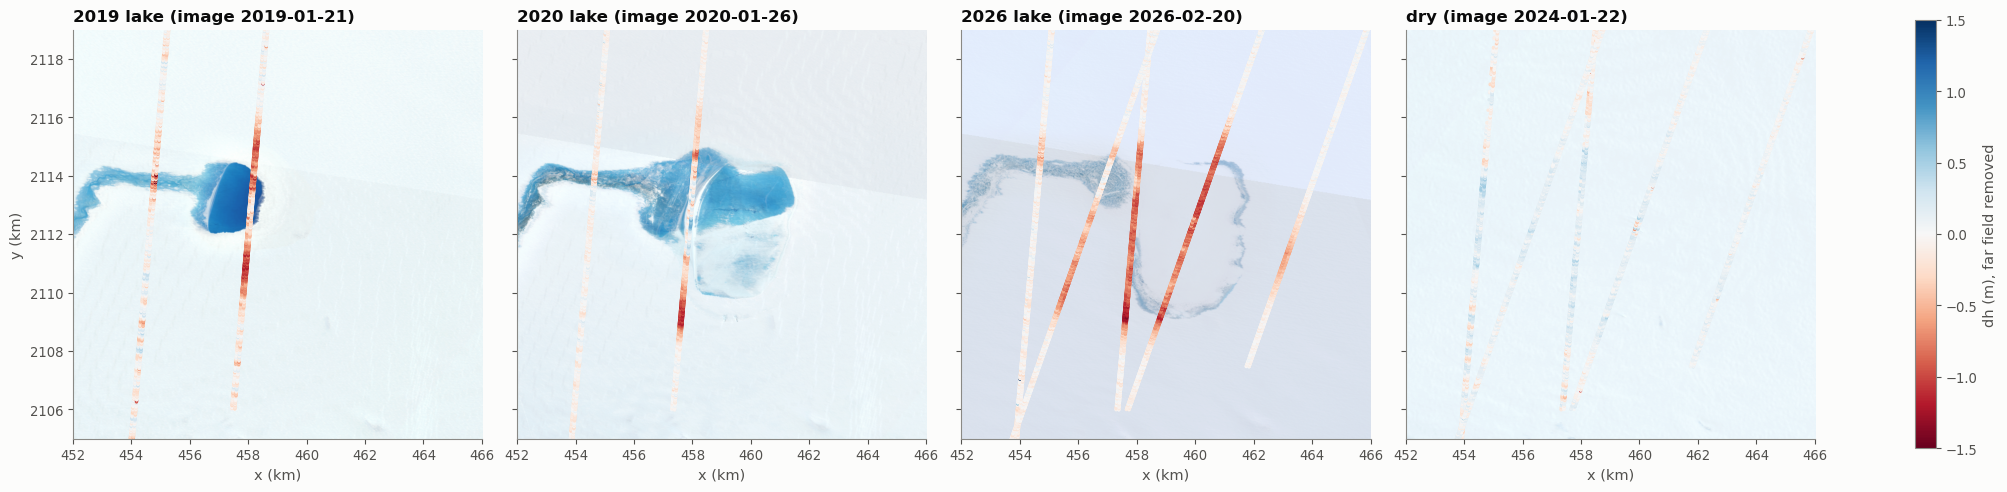

In [19]:
fig, axs = plt.subplots(1, 4, figsize=(20, 6.2), sharex=True, sharey=True, constrained_layout=True)
panels = [("2019 lake", [762], "2019"), ("2020 lake", [762], "2020"), ("2026 lake", [762, 312], "2026"),
          ("dry", [762, 312], "2024")]
for ax, (name, rgts, yr) in zip(axs, panels):
    ax.imshow(it.rgb(scenes[yr]), extent=ext, alpha=0.9)
    for (en, rgt), d in ev.items():
        if en.startswith(name) and rgt in rgts and "January" not in en:
            sc = ax.scatter(d.x / 1e3, d.y / 1e3, c=d.dh, s=2, cmap="RdBu", vmin=-1.5, vmax=1.5, rasterized=True)
    ax.set_title(f"{name} (image {scenes[yr].date})")
    ax.set_xlabel("x (km)"); ax.set_aspect("equal"); ax.grid(False)
    ax.set(xlim=(452, 466), ylim=(2105, 2119))
axs[0].set_ylabel("y (km)")
fig.colorbar(sc, ax=axs, shrink=0.7, label="dh (m), far field removed");

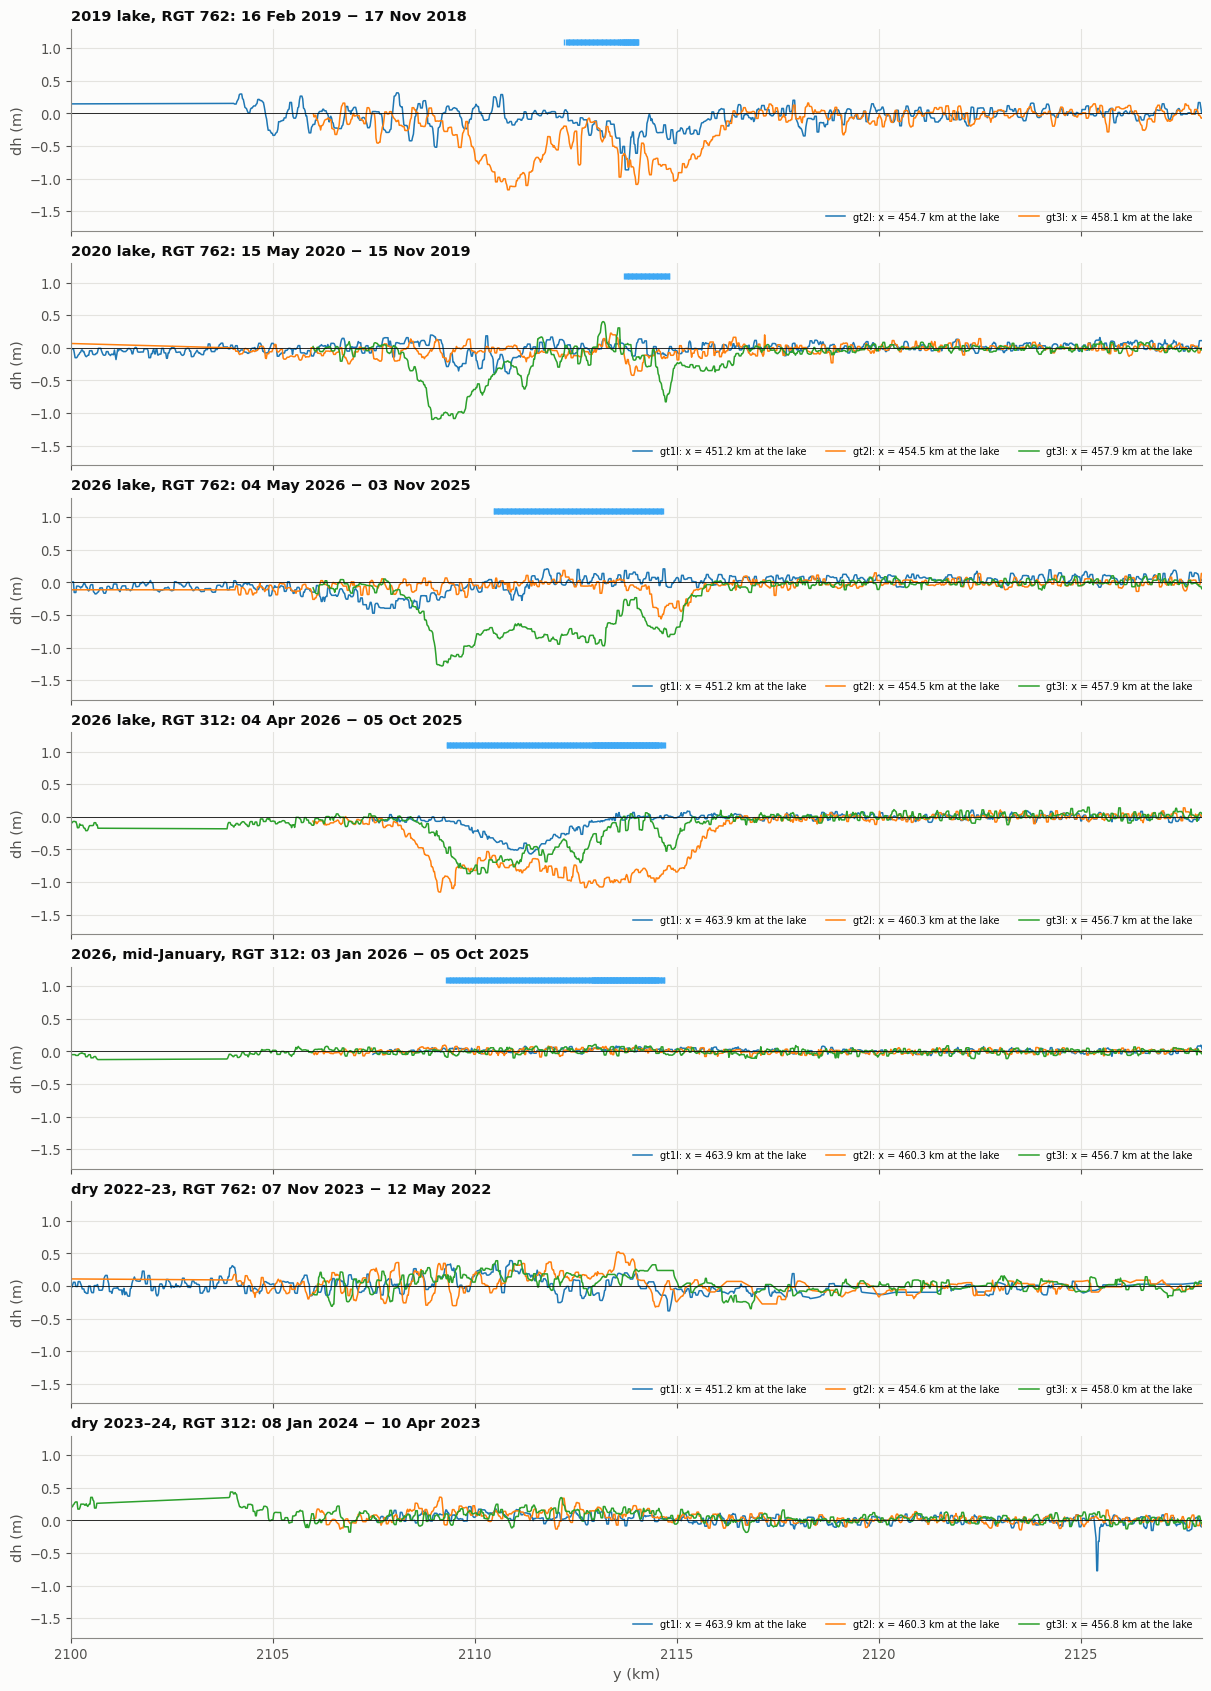

In [20]:
fig, axs = plt.subplots(len(EVENTS), 1, figsize=(12, 2.4 * len(EVENTS)), sharex=True, constrained_layout=True)
for ax, ((name, rgt, ca, cb, yr), d) in zip(axs, zip(EVENTS, ev.values())):
    for beam, q in d.groupby("beam"):
        if beam % 20 != 10:                       # one beam of each pair is enough
            continue
        xl = np.interp(LAKE19[1], q.y, q.x)       # where the beam passes the lake's latitude
        ax.plot(q.y / 1e3, it.smooth(q.dh), lw=1.1, label=f"gt{(beam // 10 + 1) // 2}{'l' if (beam // 10) % 2 else 'r'}: x = {xl / 1e3:.1f} km at the lake")
        inl = lakes[yr].sel(x=xr.DataArray(q.x.values), y=xr.DataArray(q.y.values), method="nearest").values
        if inl.any() and yr != "2024":
            ax.plot(q.y.values[inl] / 1e3, np.full(inl.sum(), 1.1), "|", ms=4, color=ps.WATER)
    ax.axhline(0, color=ps.INK, lw=0.6)
    ax.set(ylim=(-1.8, 1.3), ylabel="dh (m)")
    ax.set_title(f"{name}, RGT {rgt}: {d.time.iloc[0]:%d %b %Y} − {d.time_ref.iloc[0]:%d %b %Y}", fontsize=10.5)
    ax.legend(fontsize=7, loc="lower right", ncol=3)
axs[-1].set(xlabel="y (km)", xlim=(2100, 2128));

Blue ticks along the top of each panel mark where the beam crosses that summer's mapped water (the 2026 footprint for 2026). One beam of each pair is shown; its x is given where it passes the lake's latitude.

* **Every fill lowers the surface by about 1 m over and around the flooded area.** Nothing else on the 40 km tracks moves by more than about 0.2 m.
* **The dry summers show nothing.** The repeat differences are flat to about ±0.1–0.2 m along the whole track, so 0.2 m is roughly the detection floor once the far field is removed.
* **2026, RGT 312** gives a clean experiment. On 3 January, before the lake had formed, nothing had changed. By 4 April the surface had dropped by ~1 m over a 6–7 km stretch with steep sides, right across the 2026 lake. The pairs 3.6 km to either side dropped less (0.5–0.8 m), including the eastern one, which runs ~2 km outside the mapped footprint.
* **2020, RGT 762:** the largest drop (~1.1 m) is just south of the 2019 lake. That is where the 2020 image shows the pale slushy or refrozen area.

### How sharp are the edges?

A uniform load spread over an area much wider than $\ell$ sinks the shelf evenly in the middle. At the load's edge the plate smooths the step over a few flexural lengths (Hetényi's solution, `it.load_edge`). Fitting that edge to the 2026 RGT 312 profile across the flooded area gives an upper bound on the effective $\ell$: the load's own edge may be gradual too.

,edge,sag_m,edge_y_km,ell_m,ell_sd_m
0,south,0.68,2108.54,240.14,27.30
1,north,0.89,2115.53,506.51,21.57


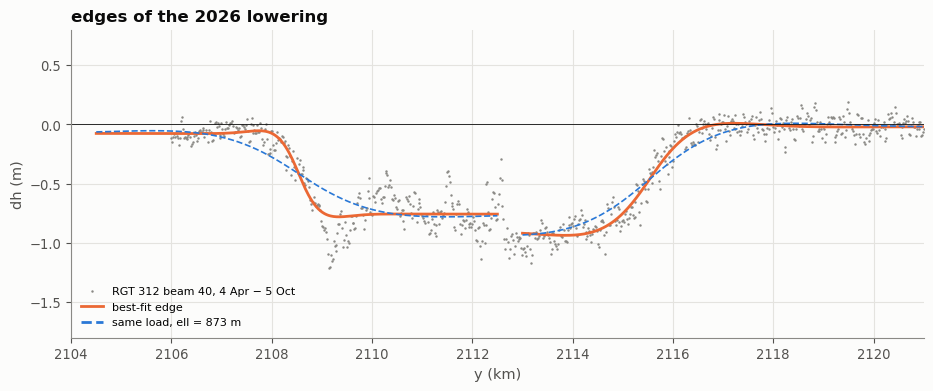

In [21]:
d = ev[("2026 lake", 312)]
beam = d.groupby("beam").x.median().sub(460.2e3).abs().idxmin()
q = d[d.beam == beam].sort_values("y")
edge_fits = []
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(q.y / 1e3, q.dh, ".", ms=1.5, color=ps.MUTED, label=f"RGT 312 beam {beam}, 4 Apr − 5 Oct")
for (lo, hi), sign, guess in [((2104.5e3, 2112.5e3), 1, 2109e3), ((2113e3, 2121e3), -1, 2116e3)]:
    s = q[(q.y > lo) & (q.y < hi)]
    f = lambda y, A, s0, ell, c: it.load_edge(y, A, s0, ell, c, sign=sign)
    p, cov = curve_fit(f, s.y, s.dh, p0=[1.0, guess, 300, 0], bounds=([0, lo, 20, -1], [3, hi, 5000, 1]))
    edge_fits.append(dict(edge="south" if sign > 0 else "north", sag_m=p[0], edge_y_km=p[1] / 1e3, ell_m=p[2],
                          ell_sd_m=np.sqrt(cov[2, 2])))
    yy = np.linspace(lo, hi, 400)
    ax.plot(yy / 1e3, f(yy, *p), color=ps.ELASTIC, lw=2)
    ax.plot(yy / 1e3, f(yy, p[0], p[1], 873.0, p[3]), color=ps.VISCO, lw=1.2, ls="--")
ax.plot([], [], color=ps.ELASTIC, label="best-fit edge")
ax.plot([], [], color=ps.VISCO, ls="--", label="same load, ell = 873 m")
ax.axhline(0, color=ps.INK, lw=0.6)
ax.set(xlabel="y (km)", ylabel="dh (m)", xlim=(2104, 2121), ylim=(-1.8, 0.8), title="edges of the 2026 lowering")
ax.legend(fontsize=8, loc="lower left")
pd.DataFrame(edge_fits)

Both edges of the 2026 lowering are steep. The fitted $\ell$ is about 240 m on the south edge and about 510 m on the north edge, no wider than the tidal flexural length. With the routing notebook's $\ell$ = 873 m the same load would smear the south edge over 2–3 km, which is clearly too smooth. So whatever lowered the surface in 2026 had a sharp-edged footprint 6–7 km across, and the shelf supported it almost locally.

## 9. Does the lowering last? Seven years on RGT 762

Every later pass of RGT 762 is compared below with the pre-melt pass of 17 November 2018, using the beam through the lake and the same far-field referencing. The zones are the dry ice south and north of the 2019 lake and the 2019 lake itself, along that beam.

,time,cycle,far_sd,south of the 2019 lake,2019 lake,north of the 2019 lake
0,2019-02-16 09:10:16.379070976,2,0.11,-0.93,-0.44,-0.81
1,2019-05-18 04:49:54.813765888,3,0.11,-0.92,0.01,-0.70
2,2019-11-15 20:09:34.549806592,5,0.11,-0.78,0.14,-0.58
3,2020-05-15 11:29:06.678281728,7,0.10,-1.19,0.11,-0.97
4,2021-05-13 18:08:26.847912192,11,0.11,-1.22,0.34,-0.94
5,2021-11-11 09:28:19.332750080,13,0.11,-1.01,0.60,-0.90
6,2022-02-10 05:08:06.224206592,14,0.11,-1.06,0.57,-0.90
7,2022-05-12 00:48:04.060461568,15,0.11,-1.00,0.57,-0.89
8,2023-11-07 22:45:47.777498368,21,0.15,-0.77,0.69,-0.85
9,2024-08-06 09:44:51.766678528,24,0.14,-0.57,0.82,-0.47


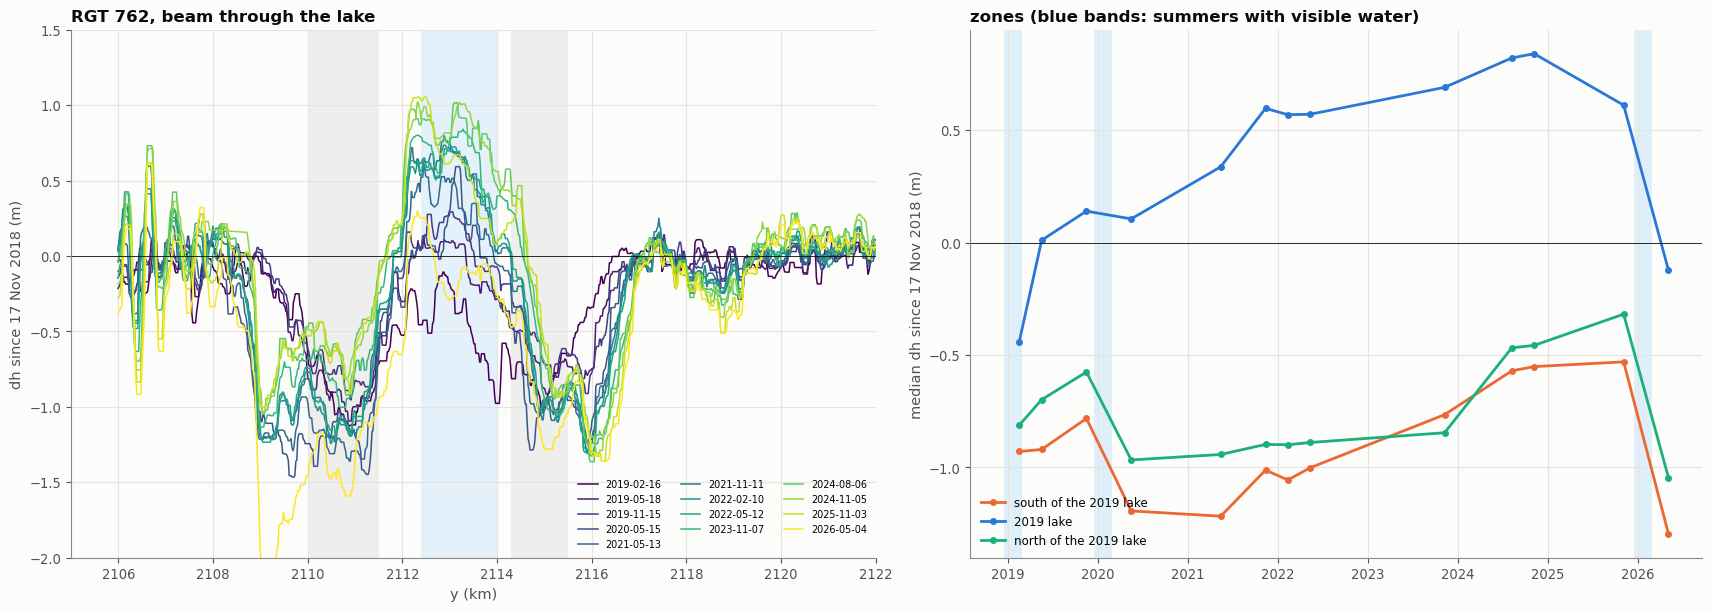

In [22]:
later = sorted(atl[(atl.rgt == 762) & (atl.cycle >= 2)].cycle.unique())
hov, zrows = [], []
ZONES = {"south of the 2019 lake": (2110.0e3, 2111.5e3), "2019 lake": (2112.4e3, 2114.0e3),
         "north of the 2019 lake": (2114.3e3, 2115.5e3)}
for c in later:
    d = it.pass_difference(atl, 762, 1, c, max_sep=600, far=far, beams=[50])
    if len(d) < 500:
        continue
    d = d[d.dgl > 1500]
    if len(d) < 500:
        continue
    hov.append(d)
    zrows.append({"time": d.time.iloc[0], "cycle": c, "far_sd": d[d.far].dh.std(),
                  **{k: d[d.y.between(*v)].dh.median() for k, v in ZONES.items()}})
zt = pd.DataFrame(zrows)

fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1.1, 1]), constrained_layout=True)
cm = plt.cm.viridis
for k, d in enumerate(hov):
    axs[0].plot(d.y / 1e3, it.smooth(d.dh, 9), color=cm(k / (len(hov) - 1)), lw=1.1, label=f"{d.time.iloc[0]:%Y-%m-%d}")
for k, (zn, (lo, hi)) in enumerate(ZONES.items()):
    axs[0].axvspan(lo / 1e3, hi / 1e3, color=[ps.MUTED, ps.WATER, ps.MUTED][k], alpha=0.12, lw=0)
axs[0].axhline(0, color=ps.INK, lw=0.6)
axs[0].set(xlim=(2105, 2122), ylim=(-2, 1.5), xlabel="y (km)", ylabel="dh since 17 Nov 2018 (m)",
           title="RGT 762, beam through the lake")
axs[0].legend(fontsize=7, ncol=3, loc="lower right")
for (zn, c) in zip(ZONES, [ps.ELASTIC, ps.VISCO, ps.ISO]):
    axs[1].plot(zt.time, zt[zn], "o-", color=c, label=zn, ms=4)
for yr in (2019, 2020, 2026):
    axs[1].axvspan(pd.Timestamp(f"{yr - 1}-12-15"), pd.Timestamp(f"{yr}-02-28"), color=ps.WATER, alpha=0.15, lw=0)
axs[1].axhline(0, color=ps.INK, lw=0.6)
axs[1].set(ylabel="median dh since 17 Nov 2018 (m)", title="zones (blue bands: summers with visible water)")
axs[1].legend(fontsize=8.5, loc="lower left")
zt.round(2)

* **The lowering persists for years.** The dry ice beside the 2019 lake stays 0.6–1.2 m down through 2023. After the 2020 lake it is deeper (−1.2 m south of the lake by May 2020). It recovers to about −0.3 to −0.5 m by 2024–25, and drops again by about 0.7 m with the 2026 lake.
* **The frozen 2019 lake rises slowly against the far field**, to +0.6–0.8 m by 2022–2024, then drops by ~0.7 m in 2026. The rise could be snow drifting onto a flat, frozen lake surface, freezing expansion, or the shelf rising slowly as the load relaxes or the ice thins.
* **A relaxing plate cannot produce this.** Flexural sag outside a load fades within months on the routing notebook's plate. A lowering that sits for years and steps down only when water returns behaves like local changes in mass and thickness (stored water, compaction) under near-local isostasy.

## 10. Summary: what ICESat-2 can detect here

* **The basin fills intermittently.** The routing notebook's big depression contains the terminal lake of the WS, M and ES channels. Every Sentinel-2 image from 2018 to 2026 shows water there in **2019, 2020 and 2026 only**: a deep, round lake in 2019, a larger one in 2020, and in 2026 a 4–5 km lake that was largely ice-covered by February. There was no lake in 2021–2025 (January 2021 was cloudy; a small pond appeared in March 2025), and none in the 2014–2018 Landsat 8 and Sentinel-2 images either.
* **Where water covered dry snow, ICESat-2 sees the shelf sink under it.** On 16 January 2020, RGT 312 crossed 5.7 km of new water whose bed ATL03 can see: median 7.8 m deep, up to 8.9 m. The water surface lay within 0.2 m of the snow surface measured on the same track nine months earlier. On a rigid shelf it would stand ~8 m higher. The elastic plates leave it 1–4 m higher near the shores; local isostasy puts it +0.2 m. The floor therefore sank ~7.8 m: the long-time, near-isostatic limit of the viscoelastic plate, not its instantaneous elastic response.
* **The shores sank as well.** At both ends of that crossing the water lies 0.9–1.9 m below the old snow surface. Local isostasy cannot do that. The dips match the edges of an $\ell \approx$ 0.5 km plate: a viscoelastic plate whose broad interior has relaxed but whose sharp edges have not.
* **Where the water replaced an older surface,** in the 2019 lake and in the 2019 lake reopened in 2020, the water surface is likewise within ±0.2 m of the surface it replaced. No bed is seen there, so the depth is unknown.
* **Each fill also lowers the surface around the water by ~1 m, out to 2–3 km beyond the mapped water.** The 5th percentile of `dh` within 4 km of the basin is −1.0 to −1.15 m for the 2019, 2020 and 2026 fills. Dry summers give no signal: `dh` scatters by 0.08–0.13 m, and 0.2 m is roughly the detection floor once the far field is removed. RGT 312 times the 2026 fill: nothing on 3 January, ~1 m by 4 April.
* **The ring of lowering is not elastic flexure under the visible lake.** Tidal flexure at the nearby grounding line gives an effective flexural length of ~500 m (interquartile 390–575 m), i.e. $E \approx$ 0.1–0.3 GPa for $H$ = 300–400 m. A plate that stiff confines the sag to within ~1 km of the shore. The ring holds more volume (~25 Mm³ if axisymmetric) than the 2019 lake could support (17 Mm³). The edges of the 2026 lowering fit $\ell$ ≈ 240–510 m. And the ring lasts for years after freeze-up.
* **The likely reading:** each fill delivers water to a wider area of the basin's firn than the open lake. The shelf sinks almost isostatically under that stored water, and the snowpack melts and compacts. Flexure only smooths the edges over a few hundred metres. For the routing notebook this argues for (i) the viscoelastic plate's long-time behaviour, (ii) a stiffness nearer $\ell \approx$ 0.5 km than 0.87 km, and (iii) a load that includes water stored in the firn.
* **Amery's Central Terminal Lake** ([`icesat2_ctl_amery.ipynb`](icesat2_ctl_amery.ipynb)) gives the same near-zero offset between water surface and winter surface. But that lake re-forms each year on its own frozen predecessor, and the fast flow there adds ±0.5 m of advected topography, so it is a weaker test than this basin.

**Caveats.** REMA is an undated mosaic, so the topography between paired tracks cancels only as well as REMA resolves it; that matters most for the November 2018 pass, 230–450 m from later passes. The plate predictions in Section 6 use a 1-D beam along the track, which overstates the bending at the edges of a lake that is finite in the other direction. One alternative fits the 2020 crossing without the shelf sinking: an ~8 m hollow already filled flush with snow before the water came. It would not, however, lower the shores. Stored water and firn compaction cannot be told apart with altimetry alone.

**Next steps.**

* Repeat the bed retrieval on other wet crossings (shallower water, other beams) to map the load in more places.
* Use Sentinel-1 backscatter to map buried slush around the lake in 2019 and 2026.
* Run the coupled model (`route_with_flexure`) with this basin's real melt and compare its water surface and bed with the 16 January 2020 crossing. That is the most direct check of the model's relaxed response.
* Fit the persistent lowering with a firn-compaction model to separate thickness change from load.